In [61]:
# Python version: 3.9.17

# Imports

In [62]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from Bio.PDB.Polypeptide import three_to_one, one_to_three
from sklearn.metrics import pairwise_distances
import matplotlib.colors as mcolors
import string
from scipy.stats import fisher_exact, mannwhitneyu
import itertools
import re

In [63]:
input_folder = Path('../1_inputs')
output_folder = Path('../3_outputs')

os.makedirs(input_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)
os.makedirs(output_folder / 'figs', exist_ok=True)
os.makedirs(output_folder / 'network', exist_ok=True)

# Loading and processing data

## Abundance and PPI

In [65]:
# Loading MVK data for abundance and PPI from individual assays

ppi_input_path = Path('../../2_individual_assay_results/ppi/3_outputs/sqY2H/ppi_level_scores_minimal_update3.csv')
# ppi_input_path = Path('../../2_individual_assay_results/ppi/3_outputs/sqY2H/MVK_no_seq_df.csv')
abundance_input_path = Path('../../2_individual_assay_results/dual_ipa/3_outputs/dualipa_abundance_scores_DACC.csv')

ppi_df = pd.read_csv(ppi_input_path)
abundance_df = pd.read_csv(abundance_input_path)

mvk_ppi_df = (
    ppi_df[ppi_df['symbol'] == 'MVK']
    .copy()
    [['aa_change', 'log2fc', 'consensus_score', 'wt_consensus_score']]
    .rename(columns={'log2fc': 'ppi_score'})
)

mvk_abundance_df = (
    abundance_df[abundance_df['symbol'] == 'MVK']
    .copy()
    [['aa_change', 'dualipa_abun_score', 'dualipa_abun_change', 'dualipa_abun_chg_dir']]
    .rename(columns={'dualipa_abun_score': 'z_abundance_change'})
)

mvk_abundance_ppi_df = mvk_ppi_df.merge(mvk_abundance_df, on='aa_change', how='outer')
mvk_abundance_ppi_df

,aa_change,ppi_score,consensus_score,wt_consensus_score,z_abundance_change,dualipa_abun_change,dualipa_abun_chg_dir
0,Ala148Thr,-2.863850,62.509654,461.321981,-0.381552,N,Decrease
1,Arg106His,NaN,NaN,NaN,-2.174017,Uncertain,Decrease
2,Arg277Cys,NaN,NaN,NaN,-0.789593,Uncertain,Decrease
3,Asn205Asp,-1.332022,182.639429,461.321981,-0.043331,N,Decrease
4,Asn301Thr,-4.275813,22.866928,461.321981,-3.704403,Y,Decrease
5,Cys101Tyr,0.516302,660.251718,461.321981,0.286346,N,Increase
6,Cys367Ser,NaN,NaN,NaN,-2.174913,Uncertain,Decrease
7,Gly211Ala,NaN,NaN,NaN,-7.417244,Y,Decrease
8,His20Pro,-4.404054,20.836963,461.321981,1.025132,Uncertain,Increase
9,Ile119Met,NaN,NaN,NaN,-0.958659,Uncertain,Decrease


In [67]:
ppi_df.columns

Index(['symbol', 'aa_change', 'db_mut_id', 'ad_symbol',
       'clinvar_clnsig_clean_pp_strict', 'consensus_score',
       'wt_consensus_score', 'log2fc'],
      dtype='object')

In [ ]:
mvk_abundance_ppi_df

,aa_change,ppi_score,consensus_score,wt_consensus_score,z_abundance_change,dualipa_abun_change,dualipa_abun_chg_dir
0,Ala148Thr,-2.863850,62.509654,461.321981,-0.381552,N,Decrease
1,Arg106His,NaN,NaN,NaN,-2.174017,Uncertain,Decrease
2,Arg277Cys,NaN,NaN,NaN,-0.789593,Uncertain,Decrease
3,Asn205Asp,-1.332022,182.639429,461.321981,-0.043331,N,Decrease
4,Asn301Thr,-4.275813,22.866928,461.321981,-3.704403,Y,Decrease
5,Cys101Tyr,0.516302,660.251718,461.321981,0.286346,N,Increase
6,Cys367Ser,NaN,NaN,NaN,-2.174913,Uncertain,Decrease
7,Gly211Ala,NaN,NaN,NaN,-7.417244,Y,Decrease
8,His20Pro,-4.404054,20.836963,461.321981,1.025132,Uncertain,Increase
9,Ile119Met,NaN,NaN,NaN,-0.958659,Uncertain,Decrease


## Functional assay

In [ ]:
mvk_df = pd.read_csv(input_folder / 'mvk_func_assay_coordinates.tsv', sep='\t')
mvk_df

,Unnamed: 0,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,z_abundance_change,ppi_score
0,0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,0.144154,"{(281.0, 1.0)}"
1,1,281,1156G>A,Asp386Asn,MVK,ENSG00000110921,Benign,28.0,vus,2,B01,-1.660505,"{(281.0, 1.0)}"
2,2,281,238G>A,Val80Ile,MVK,ENSG00000110921,Conflicting,6.0,vus,3,C01,-0.813608,"{(281.0, 1.0)}"
3,3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,0.539184,"{(281.0, 0.0)}"
4,4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,-1.951288,"{(281.0, 0.0)}"
5,5,281,357C>G,Ile119Met,MVK,ENSG00000110921,Pathogenic,200087.0,cegs,6,F01,-0.786116,"{(281.0, 1.0)}"
6,6,281,404C>T,Ser135Leu,MVK,ENSG00000110921,Pathogenic,200088.0,cegs,7,G01,NaN,NaN
7,7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,NaN,NaN
8,8,281,625A>G,Thr209Ala,MVK,ENSG00000110921,Pathogenic,200091.0,cegs,9,A02,-0.264209,"{(281.0, 1.0)}"
9,9,281,632G>C,Gly211Ala,MVK,ENSG00000110921,Pathogenic,200092.0,cegs,10,B02,-2.609396,"{(281.0, 0.0)}"


In [ ]:
# Loading MVK data layout from the complementation assay

mvk_df = pd.read_csv(input_folder / 'mvk_func_assay_coordinates.tsv', sep='\t')
mvk_df.drop(['Unnamed: 0'], axis=1, inplace=True)

# Based on the pictures in the keynote MVK - functional assay.key
# Array to add the growth results in the dataframe

growth_col = [1,1,1,1,1,1,0,1,
              1,0,0,1,1,0,1,1,
              1,0,1,1,0,0,0,1,
              1,1,1,0,1,1,1,1,
              1,1,1,1,1,1,1,1,
              1,1,1,1]

mvk_df['growth'] = growth_col

col_to_keep = ['orf_id', 'nt_change', 'aa_change', 'symbol', 'ensg',
      'mut_id', 'growth']

mvk_growth_df = mvk_df[col_to_keep].copy()
mvk_growth_df.drop(index=40, inplace=True) # drop the allele that wasn't spotted
mvk_growth_df.to_csv(output_folder / 'mvk_growth_df.tsv', sep='\t', index=False) # save a table with the growth results


In [ ]:
mvk_df

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,z_abundance_change,ppi_score,growth
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,0.144154,"{(281.0, 1.0)}",1
1,281,1156G>A,Asp386Asn,MVK,ENSG00000110921,Benign,28.0,vus,2,B01,-1.660505,"{(281.0, 1.0)}",1
2,281,238G>A,Val80Ile,MVK,ENSG00000110921,Conflicting,6.0,vus,3,C01,-0.813608,"{(281.0, 1.0)}",1
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,0.539184,"{(281.0, 0.0)}",1
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,-1.951288,"{(281.0, 0.0)}",1
5,281,357C>G,Ile119Met,MVK,ENSG00000110921,Pathogenic,200087.0,cegs,6,F01,-0.786116,"{(281.0, 1.0)}",1
6,281,404C>T,Ser135Leu,MVK,ENSG00000110921,Pathogenic,200088.0,cegs,7,G01,NaN,NaN,0
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,NaN,NaN,1
8,281,625A>G,Thr209Ala,MVK,ENSG00000110921,Pathogenic,200091.0,cegs,9,A02,-0.264209,"{(281.0, 1.0)}",1
9,281,632G>C,Gly211Ala,MVK,ENSG00000110921,Pathogenic,200092.0,cegs,10,B02,-2.609396,"{(281.0, 0.0)}",0


In [ ]:
# # Edgotyping data

# edgotyping_file_path = Path('../../2_individual_assay_results/ppi/3_outputs/sqY2H/normalized_consensus_scores.csv')

# edgotyping_df = pd.read_csv(edgotyping_file_path, sep=',')
# mvk_edgotyping_df = edgotyping_df[edgotyping_df['db_orf_id'] == 281]
# mvk_edgotyping_df

In [ ]:
# Loading MVK data layout from the complementation assay

mvk_df = pd.read_csv(input_folder / 'mvk_func_assay_coordinates.tsv', sep='\t')
mvk_df.drop(['Unnamed: 0'], axis=1, inplace=True)

# Based on the pictures in the keynote MVK - functional assay.key
# Array to add the growth results in the dataframe
growth_col = [1,1,1,1,1,1,0,1,
              1,0,0,1,1,0,1,1,
              1,0,1,1,0,0,0,1,
              1,1,1,0,1,1,1,1,
              1,1,1,1,1,1,1,1,
              1,1,1,1]

mvk_df['growth'] = growth_col

col_to_keep = ['orf_id', 'nt_change', 'aa_change', 'symbol', 'ensg',
      'mut_id', 'growth']

mvk_growth_df = mvk_df[col_to_keep].copy()
mvk_growth_df.to_csv(output_folder / 'mvk_growth_df.tsv', sep='\t', index=False)

# Map sqY2H log2 fold-change and DUAL-IPA abundance results from the individual assays
ppi_lookup = mvk_abundance_ppi_df.set_index('aa_change')['ppi_score']
abundance_lookup = mvk_abundance_ppi_df.set_index('aa_change')['z_abundance_change']
change_lookup = mvk_abundance_ppi_df.set_index('aa_change')

mvk_df['ppi_score'] = mvk_df['aa_change'].map(ppi_lookup)
mvk_df['z_abundance_change'] = mvk_df['aa_change'].map(abundance_lookup)
mvk_df['dualipa_abun_change'] = mvk_df['aa_change'].map(change_lookup['dualipa_abun_change'])
mvk_df['dualipa_abun_chg_dir'] = mvk_df['aa_change'].map(change_lookup['dualipa_abun_chg_dir'])


mvk_df = mvk_df.iloc[:-4]  # remove the last 3 rows (controls) + Arg388Gln which was not spotted but present in the dataframe

# # Filtering the dataframe for variants where we have PPI data and abundance data
mvk_df = mvk_df[mvk_df['ppi_score'].notna()]
mvk_df = mvk_df[mvk_df['z_abundance_change'].notna()]

abundance_cutoff = -1.96  # z-score threshold used previously
two_fold_ppi_threshold = -4  # log2 fold-change equivalent to a 2-fold drop in interactions

mvk_df['abundance'] = mvk_df['z_abundance_change']
# mvk_df['abundance_binary'] = mvk_df['z_abundance_change'].apply(
#     lambda x: 0 if pd.notna(x) and x < abundance_cutoff else 1 if pd.notna(x) else np.nan
# )
mvk_df['abundance_binary'] = [0 if abun == 'Y' else 1 for abun in mvk_df.dualipa_abun_change]
mvk_df['ppi_binary'] = mvk_df['ppi_score'].apply(
    lambda x: 1 if pd.notna(x) and x >= two_fold_ppi_threshold else 0 if pd.notna(x) else np.nan
)

mvk_df['ppi'] = mvk_df['ppi_binary']  # retain legacy column expected by downstream plotting

mvk_df

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,z_abundance_change,ppi_score,growth,dualipa_abun_change,dualipa_abun_chg_dir,abundance,abundance_binary,ppi_binary,ppi
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,0.321699,0.503237,1,N,Increase,0.321699,1,1,1
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,0.752852,-3.134240,1,N,Increase,0.752852,1,1,1
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,-3.704403,-4.275813,1,Y,Decrease,-3.704403,0,0,0
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,-0.381552,-2.863850,1,N,Decrease,-0.381552,1,1,1
21,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,1.025132,-4.404054,0,Uncertain,Increase,1.025132,1,0,0
27,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,-6.109241,-1.919337,0,Y,Decrease,-6.109241,0,1,1
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,-0.501169,-1.734906,1,N,Decrease,-0.501169,1,1,1
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,0.286346,0.516302,1,N,Increase,0.286346,1,1,1
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,-0.760244,-0.395951,1,Uncertain,Decrease,-0.760244,1,1,1


## ClinVar

In [ ]:
# Load ClinVar data for MVK, accessed on 2025-03-24
# Infevers used instead

mvk_clinvar_df = pd.read_csv(input_folder / 'clinvar_mvk_032524.txt', sep='\t')
mvk_clinvar_df = mvk_clinvar_df[mvk_clinvar_df.Name.str.contains('MVK')].copy() # Filter the df to remove rows linked to MMAB, the gene on the opposite strand

pattern = r"p\.(.+?)(?=\))"  # Pattern to extract the protein change from the name string

mvk_clinvar_df['protein_change'] = mvk_clinvar_df.Name.str.extract(pattern)
mvk_clinvar_df = mvk_clinvar_df.reset_index(drop=True)

mvk_clinvar_df.head()

,Name,Gene(s),Protein change,Condition(s),Accession,GRCh37Chromosome,GRCh37Location,GRCh38Chromosome,GRCh38Location,VariationID,...,Germline date last evaluated,Germline review status,Somatic clinical impact,Somatic clinical impact date last evaluated,Somatic clinical impact review status,Oncogenicity classification,Oncogenicity date last evaluated,Oncogenicity review status,Unnamed: 24,protein_change
0,NM_000431.4(MVK):c.1A>C (p.Met1Leu),MVK,M1L,"Mevalonic aciduria|Porokeratosis 3, disseminat...",VCV002925505,12,110012628,12,109574823,2925505,...,"Jan 1, 2023","criteria provided, single submitter",NaN,NaN,NaN,NaN,NaN,NaN,NaN,Met1Leu
1,NM_000431.4(MVK):c.14T>C (p.Val5Ala),MVK,V5A,not provided|Mevalonic aciduria|Hyperimmunoglo...,VCV000234376,12,110012641,12,109574836,234376,...,"Jan 1, 2024","criteria provided, multiple submitters, no con...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,Val5Ala
2,NM_000431.4(MVK):c.17T>A (p.Leu6Gln),MVK,L6Q,Inborn genetic diseases,VCV002230583,12,110012644,12,109574839,2230583,...,"Jan 1, 2021","criteria provided, single submitter",NaN,NaN,NaN,NaN,NaN,NaN,NaN,Leu6Gln
3,NM_000431.4(MVK):c.22G>C (p.Val8Leu),MVK,V8L,Hyperimmunoglobulin D with periodic fever,VCV000097577,12,110012649,12,109574844,97577,...,NaN,no classification provided,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Val8Leu
4,NM_000431.4(MVK):c.29C>T (p.Ala10Val),MVK,A10V,not provided,VCV000872779,12,110012656,12,109574851,872779,...,"Jan 1, 2020","criteria provided, single submitter",NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ala10Val


## Infevers

In [ ]:
# Phenotypes and clinical significance data retrieved from Infevers (05/15/2024)
# HIDS = Hyper-IgD Syndrome
# MVA = Mevalonate Aciduria
# PK = Porokeratosis type 3
# MKD = Mevalonate Kinase Deficiency, when both HIDS and MVA are reported


condition_mapping_dict = {1:'HIDS',
2:'MVA',
3:'MKD',
4:'PK'}

infevers_conditions = {'Ser52Asn':np.nan,
'Asp386Asn':1,
'Val80Ile':np.nan,
'Pro167Leu':1,
'Asn301Thr':2,
'Ile119Met':1,
'Ala148Thr':1,
'Thr209Ala':1,
'Gly211Ala':1,
'Thr243Ile':2,
'Val250Ile':1,
'Leu265Pro':2,
'Val293Met':1,
'Ser329Asn':1,
'His20Pro':3,
'Leu41Pro':4,
'Tyr116His':3,
'Pro165Leu':1,
'Leu255Pro':4,
'Ile268Val':1,
'Ile268Thr':3,
'Val377Ile':3,
'Pro288Leu':1,
'Val5Ala':1,
'Cys101Tyr':np.nan,
'Arg106His':np.nan,
'Pro200Ser':np.nan,
'Val278Met':np.nan,
'Pro286Leu':np.nan,
}

infevers_conditions_names = {k:condition_mapping_dict[v] if v == v else np.nan for k,v in infevers_conditions.items()}

infevers_sign = {'Ser52Asn':'Benign',
'Asp386Asn':'VUS',
'Val80Ile':'Benign',
'Pro167Leu':'Pathogenic',
'Asn301Thr':'Pathogenic',
'Ile119Met':'Pathogenic',
'Ala148Thr':'Pathogenic',
'Thr209Ala':'Pathogenic',
'Gly211Ala':'Pathogenic',
'Thr243Ile':'Pathogenic',
'Val250Ile':'Pathogenic',
'Leu265Pro':'Pathogenic',
'Val293Met':'VUS',
'Ser329Asn':'Pathogenic',
'His20Pro':'Pathogenic',
'Leu41Pro':'Pathogenic',
'Pro165Leu':'Pathogenic',
'Leu255Pro':'VUS',
'Ile268Val':np.nan,
'Ile268Thr':'Pathogenic',
'Val377Ile':'Pathogenic',
'Pro288Leu':'VUS',
'Val5Ala':'VUS',
'Cys101Tyr':np.nan,
'Arg106His':np.nan,
'Pro200Ser':np.nan,
'Val278Met':np.nan,
'Pro286Leu':'VUS'
}

mvk_df['phenotype_infevers'] = mvk_df['aa_change'].map(infevers_conditions_names)
mvk_df['phenotype_infevers_ids'] = mvk_df['aa_change'].map(infevers_conditions)
mvk_df['clinical_significance_infevers'] = mvk_df['aa_change'].map(infevers_sign)
mvk_df

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,growth,dualipa_abun_change,dualipa_abun_chg_dir,abundance,abundance_binary,ppi_binary,ppi,phenotype_infevers,phenotype_infevers_ids,clinical_significance_infevers
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,...,1,N,Increase,0.321699,1,1,1,NaN,NaN,Benign
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,1,N,Increase,0.752852,1,1,1,HIDS,1.0,Pathogenic
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,...,1,Y,Decrease,-3.704403,0,0,0,MVA,2.0,Pathogenic
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,...,1,N,Decrease,-0.381552,1,1,1,HIDS,1.0,Pathogenic
21,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,...,0,Uncertain,Increase,1.025132,1,0,0,MKD,3.0,Pathogenic
27,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,...,0,Y,Decrease,-6.109241,0,1,1,PK,4.0,VUS
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,1,N,Decrease,-0.501169,1,1,1,HIDS,1.0,NaN
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,1,N,Increase,0.286346,1,1,1,NaN,NaN,NaN
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,1,Uncertain,Decrease,-0.760244,1,1,1,NaN,NaN,NaN


## PoPMuSiC

Secondary structure assignment according to DSSP:

- T = hydrogen bonded turn
- G = 3-turn helix
- H = 4-turn helix
- I = 5-turn helix
- B = residue in isolated B-bridge (single pair beta-sheet hydrogen bond formation)
- E = extended strand in parralel and/or anti-parallel beta-sheet conformation (minimal length of two residues)
- S = bend (only assignment not baed on hydrogen bond)
- C = coil (residue which is not in any of the above conformation)


In [ ]:
# PoPMuSiC results on the AlphaFold structure
# Retrieve predicted ddG, secondary structure and solvent accessibility for each variant

pop_file = input_folder / 'popmusic_AF/result_44130/query_44130.pop'

pop_dict = {}

with open(pop_file, 'r') as f:
    lines = f.readlines()
    lines = lines[13:]
    for line in lines:
        line = line.replace('   ', ' ')
        line = line.replace('  ', ' ')
        chain, pos, ref, alt, ss, sa, ddg = line.split(' ')
        variant = f'{ref.lower().capitalize()}{pos}{alt.lower().capitalize()}'
        pop_dict[variant] = [ss, float(sa), float(ddg.strip())]
        
def map_to_columns(aa_change):
    values = pop_dict[aa_change]
    return values[0], values[1], values[2]

mvk_df['secondary_structure'], mvk_df['solvent_accessibility'], mvk_df['ddg'] = zip(*mvk_df['aa_change'].apply(map_to_columns))
mvk_df    

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,abundance,abundance_binary,ppi_binary,ppi,phenotype_infevers,phenotype_infevers_ids,clinical_significance_infevers,secondary_structure,solvent_accessibility,ddg
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,...,0.321699,1,1,1,NaN,NaN,Benign,E,17.94,0.70
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,0.752852,1,1,1,HIDS,1.0,Pathogenic,C,13.28,0.86
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,...,-3.704403,0,0,0,MVA,2.0,Pathogenic,H,0.00,0.40
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,...,-0.381552,1,1,1,HIDS,1.0,Pathogenic,H,0.00,1.12
21,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,...,1.025132,1,0,0,MKD,3.0,Pathogenic,T,3.72,2.00
27,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,...,-6.109241,0,1,1,PK,4.0,VUS,H,63.42,0.59
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,-0.501169,1,1,1,HIDS,1.0,NaN,H,0.42,1.32
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,0.286346,1,1,1,NaN,NaN,NaN,C,7.03,0.70
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,-0.760244,1,1,1,NaN,NaN,NaN,H,2.48,0.78


In [ ]:
ss_mapping = {'T':1,
              'G':2,
              'H':3,
              'I':4,
              'B':5,
              'E':6,
              'S':7,
              'C':8}

mvk_df['secondary_structure_digits'] = mvk_df['secondary_structure'].map(ss_mapping)
mvk_df

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,abundance_binary,ppi_binary,ppi,phenotype_infevers,phenotype_infevers_ids,clinical_significance_infevers,secondary_structure,solvent_accessibility,ddg,secondary_structure_digits
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,...,1,1,1,NaN,NaN,Benign,E,17.94,0.70,6
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,1,1,1,HIDS,1.0,Pathogenic,C,13.28,0.86,8
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,...,0,0,0,MVA,2.0,Pathogenic,H,0.00,0.40,3
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,...,1,1,1,HIDS,1.0,Pathogenic,H,0.00,1.12,3
21,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,...,1,0,0,MKD,3.0,Pathogenic,T,3.72,2.00,1
27,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,...,0,1,1,PK,4.0,VUS,H,63.42,0.59,3
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,1,1,1,HIDS,1.0,NaN,H,0.42,1.32,3
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,1,1,1,NaN,NaN,NaN,C,7.03,0.70,8
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,1,1,1,NaN,NaN,NaN,H,2.48,0.78,3


## Mislocalization

In [ ]:
misloc_df = pd.read_csv(input_folder / 'jess_data_full.tsv', sep='\t')
misloc_df = misloc_df[misloc_df.Gene == 'MVK']


mvk_df['mislocalization'] = mvk_df['aa_change'].map(misloc_df.set_index('aa_change')['Mislocalized_both_batches'].to_dict())
mvk_df['mislocalization_binary'] = mvk_df['mislocalization'].apply(lambda x: 0 if x == True else 1 if x == False else np.nan)
mvk_df

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,ppi,phenotype_infevers,phenotype_infevers_ids,clinical_significance_infevers,secondary_structure,solvent_accessibility,ddg,secondary_structure_digits,mislocalization,mislocalization_binary
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,...,1,NaN,NaN,Benign,E,17.94,0.70,6,False,1.0
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,1,HIDS,1.0,Pathogenic,C,13.28,0.86,8,False,1.0
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,...,0,MVA,2.0,Pathogenic,H,0.00,0.40,3,NaN,NaN
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,...,1,HIDS,1.0,Pathogenic,H,0.00,1.12,3,False,1.0
21,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,...,0,MKD,3.0,Pathogenic,T,3.72,2.00,1,False,1.0
27,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,...,1,PK,4.0,VUS,H,63.42,0.59,3,True,0.0
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,1,HIDS,1.0,NaN,H,0.42,1.32,3,False,1.0
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,1,NaN,NaN,NaN,C,7.03,0.70,8,False,1.0
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,1,NaN,NaN,NaN,H,2.48,0.78,3,False,1.0


In [ ]:
import polars as pl

In [ ]:
# dualipa_outputs = "../../2_individual_assay_results/dual_ipa/3_outputs"
imaging_outputs = "../../2_individual_assay_results/imaging/3_outputs"

# dualipa = pl.read_csv(f"{dualipa_outputs}/annotated_perturbation_scores.csv", infer_schema_length=100000)
imaging = pl.read_csv(f"{imaging_outputs}/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging = imaging.filter(pl.col("symbol") == "MVK")
imaging = imaging.to_pandas()
imaging

,Gene,gene_variant,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_orig_pval,U2OS_prot_abun_t_adj_pval,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,...,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,img_pheno_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict
0,MVK,MVK_Leu41Pro,-0.580769,0.582537,-5.466681,0.001563,0.003677,0.003677,2024_01_Batch_7-8,True,...,OMIM,Rare genetic systemic or rheumatologic disease...,6,"POROKERATOSIS 3, MULTIPLE TYPES",False,0.981901,0.982752,True,True,False
1,MVK,MVK_His20Pro,0.653663,0.537559,0.034704,0.973441,0.975423,0.975423,2024_01_Batch_7-8,False,...,OMIM,Rare genetic systemic or rheumatologic disease...,6,HYPER-IgD SYNDROME; MEVALONIC ACIDURIA; HYPER-...,False,0.661425,0.668076,False,False,False
2,MVK,MVK_Leu255Pro,0.282348,0.787163,-5.096848,0.002228,0.004958,0.004958,2024_01_Batch_7-8,True,...,OMIM,Rare genetic systemic or rheumatologic disease...,6,"POROKERATOSIS 3, MULTIPLE TYPES",False,0.965242,0.952676,True,True,False
3,MVK,MVK_His20Gln,0.965066,0.371782,-0.843318,0.431380,0.486755,0.486755,2024_01_Batch_7-8,False,...,OMIM,Rare genetic systemic or rheumatologic disease...,6,"HYPER-IgD SYNDROME; POROKERATOSIS 3, MULTIPLE ...",False,0.595920,0.565173,False,False,False
4,MVK,MVK_Pro167Leu,-0.123621,0.905653,-1.711155,0.137899,0.174838,0.174838,2024_01_Batch_7-8,False,...,OMIM,Rare genetic systemic or rheumatologic disease...,6,HYPER-IgD SYNDROME; HYPER-IgD SYNDROME; MEVALO...,False,0.678875,0.664747,False,False,False
5,MVK,MVK_Pro165Leu,1.485959,0.187838,1.704313,0.139208,0.176271,0.176271,2024_01_Batch_7-8,False,...,OMIM,Rare genetic systemic or rheumatologic disease...,6,HYPER-IgD SYNDROME; HYPER-IgD SYNDROME; POROKE...,False,0.668065,0.621487,False,False,False
6,MVK,MVK_Asn205Asp,-1.923673,0.102742,-2.243574,0.066022,0.091741,0.091741,2024_01_Batch_7-8,False,...,OMIM,Rare genetic systemic or rheumatologic disease...,6,HYPER-IgD SYNDROME; HYPER-IgD SYNDROME; MEVALO...,False,0.631022,0.644470,False,False,False
7,MVK,MVK_Val250Ile,3.200225,0.018595,2.112780,0.079068,0.107741,0.107741,2024_01_Batch_7-8,False,...,OMIM,Rare genetic systemic or rheumatologic disease...,6,"HYPER-IgD SYNDROME; POROKERATOSIS 3, MULTIPLE ...",False,0.685539,0.665948,False,False,False
8,MVK,MVK_Asp386Asn,2.599567,0.040686,0.582465,0.581466,0.633595,0.633595,2024_01_Batch_7-8,False,...,OMIM,Rare genetic systemic or rheumatologic disease...,6,HYPER-IgD SYNDROME; MEVALONIC ACIDURIA; POROKE...,False,0.600011,0.596389,False,False,False
9,MVK,MVK_Val80Ile,1.460074,0.194565,-2.102678,0.080180,0.109105,0.109105,2024_01_Batch_7-8,False,...,OMIM,Rare genetic systemic or rheumatologic disease...,6,HYPER-IgD SYNDROME; MEVALONIC ACIDURIA; MEVALO...,False,0.596202,0.535749,False,False,False


In [ ]:
mvk_df['mislocalization'] = mvk_df['aa_change'].map(imaging.set_index('aa_change')['img_pheno_hit'].to_dict())
mvk_df['mislocalization_binary'] = mvk_df['mislocalization'].apply(lambda x: 0 if x == True else 1 if x == False else np.nan)
mvk_df

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,ppi,phenotype_infevers,phenotype_infevers_ids,clinical_significance_infevers,secondary_structure,solvent_accessibility,ddg,secondary_structure_digits,mislocalization,mislocalization_binary
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,...,1,NaN,NaN,Benign,E,17.94,0.70,6,NaN,NaN
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,1,HIDS,1.0,Pathogenic,C,13.28,0.86,8,False,1.0
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,...,0,MVA,2.0,Pathogenic,H,0.00,0.40,3,NaN,NaN
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,...,1,HIDS,1.0,Pathogenic,H,0.00,1.12,3,NaN,NaN
21,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,...,0,MKD,3.0,Pathogenic,T,3.72,2.00,1,False,1.0
27,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,...,1,PK,4.0,VUS,H,63.42,0.59,3,True,0.0
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,1,HIDS,1.0,NaN,H,0.42,1.32,3,False,1.0
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,1,NaN,NaN,NaN,C,7.03,0.70,8,False,1.0
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,1,NaN,NaN,NaN,H,2.48,0.78,3,False,1.0


## gnomAD

In [ ]:
gnomad_df = pd.read_csv(input_folder / 'gnomad/gnomAD_v4.1.0_ENSG00000110921_2024_05_09_14_15_01.csv')

gnomad_df['aa_change'] = [change[2:] for change in gnomad_df['Protein Consequence']]

mvk_df['gnomAD_AF'] = mvk_df['aa_change'].map(gnomad_df.set_index('aa_change')['Allele Frequency'].to_dict())
mvk_df

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,phenotype_infevers,phenotype_infevers_ids,clinical_significance_infevers,secondary_structure,solvent_accessibility,ddg,secondary_structure_digits,mislocalization,mislocalization_binary,gnomAD_AF
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,...,NaN,NaN,Benign,E,17.94,0.70,6,NaN,NaN,0.110624
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,HIDS,1.0,Pathogenic,C,13.28,0.86,8,False,1.0,0.000009
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,...,MVA,2.0,Pathogenic,H,0.00,0.40,3,NaN,NaN,0.000004
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,...,HIDS,1.0,Pathogenic,H,0.00,1.12,3,NaN,NaN,0.000008
21,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,...,MKD,3.0,Pathogenic,T,3.72,2.00,1,False,1.0,0.000010
27,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,...,PK,4.0,VUS,H,63.42,0.59,3,True,0.0,NaN
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,HIDS,1.0,NaN,H,0.42,1.32,3,False,1.0,0.000006
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,NaN,NaN,NaN,C,7.03,0.70,8,False,1.0,NaN
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,NaN,NaN,NaN,H,2.48,0.78,3,False,1.0,0.000026


## Predictors

In [ ]:
def extract_predictors_data(variant):
    
    AM_path = input_folder / 'predictors/AlphaMissense_MVK.tsv'
    ESM_path = input_folder / 'predictors/ESM1b_MVK.tsv'
    provean_path = input_folder / 'predictors/PROVEAN_MVK.tsv'
    
    AM_df = pd.read_csv(AM_path, sep ='\t')
    ESM_df = pd.read_csv(ESM_path, sep ='\t')
    provean_df = pd.read_csv(provean_path, sep='\t')
    provean_df.drop('Unnamed: 0', axis=1, inplace=True)
    
    ref3 = variant[:3]
    alt3 = variant[-3:]
    ref = three_to_one(variant[:3].upper())
    pos = int(variant[3:-3])
    alt = three_to_one(variant[-3:].upper())
    
    AM_var_df = AM_df[AM_df.protein_variant == f'{ref}{pos}{alt}'].reset_index()
    AM_value =  1 - AM_var_df.am_pathogenicity.iloc[0] # Inversing the scale for it to match the direction of ESM1b, for the coloring to match on the heatmap.
    
    ESM_value = ESM_df.loc[ESM_df['Unnamed: 0'] == alt, f'{ref} {pos}'].iloc[0]
    
    pro_pos_df = provean_df[provean_df.position == pos].reset_index(drop=True)
    provean_var_score = pro_pos_df.loc[pro_pos_df.position == pos, alt3].iloc[0]        
    
    return AM_value, ESM_value, provean_var_score


extract_predictors_data('Val377Ile')

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/Bio/PDB/Polypeptide.py:144: BiopythonDeprecationWarning: 'three_to_one' will be deprecated in a future release of Biopython in favor of 'Bio.PDB.Polypeptide.protein_letters_3to1'.
  warnings.warn(


(0.9026, -6.997, -0.56)

In [ ]:
mvk_df['AM'] = mvk_df['aa_change'].apply(lambda x: extract_predictors_data(x)[0])
mvk_df['ESM1b'] = mvk_df['aa_change'].apply(lambda x: extract_predictors_data(x)[1])
mvk_df['Provean'] = mvk_df['aa_change'].apply(lambda x: extract_predictors_data(x)[2])
mvk_df['AM_binary'] = [1 if am < 0.2 else 0 for am in mvk_df.AM]
mvk_df['ESM1b_binary'] = [1 if am < -7 else 0 for am in mvk_df.ESM1b]
mvk_df['Provean_binary'] = [1 if am < -2.5 else 0 for am in mvk_df.Provean]
mvk_df

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/Bio/PDB/Polypeptide.py:144: BiopythonDeprecationWarning: 'three_to_one' will be deprecated in a future release of Biopython in favor of 'Bio.PDB.Polypeptide.protein_letters_3to1'.
  warnings.warn(
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/Bio/PDB/Polypeptide.py:144: BiopythonDeprecationWarning: 'three_to_one' will be deprecated in a future release of Biopython in favor of 'Bio.PDB.Polypeptide.protein_letters_3to1'.
  warnings.warn(
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/Bio/PDB/Polypeptide.py:144: BiopythonDeprecationWarning: 'three_to_one' will be deprecated in a future release of Biopython in favor of 'Bio.PDB.Polypeptide.protein_letters_3to1'.
  warnings.warn(
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/Bio/PDB/Polypeptide.py:144: BiopythonDeprecationWarning: 'three_to_one' will be deprecated in a future release of Biopython in favor of 'Bio.PDB.

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,secondary_structure_digits,mislocalization,mislocalization_binary,gnomAD_AF,AM,ESM1b,Provean,AM_binary,ESM1b_binary,Provean_binary
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,...,6,NaN,NaN,0.110624,0.9159,-2.335,1.10,0,0,0
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,8,False,1.0,0.000009,0.8219,-5.542,-4.53,0,0,1
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,...,3,NaN,NaN,0.000004,0.1798,-9.155,-5.00,1,1,1
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,...,3,NaN,NaN,0.000008,0.5969,-8.153,-3.21,0,1,1
21,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,...,1,False,1.0,0.000010,0.1467,-14.191,-8.96,1,1,1
27,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,...,3,True,0.0,NaN,0.5390,-10.926,-2.80,0,1,1
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,3,False,1.0,0.000006,0.9117,-3.517,-0.37,0,0,0
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,8,False,1.0,NaN,0.8916,-4.048,-1.54,0,0,0
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,3,False,1.0,0.000026,0.8498,-8.043,-1.47,0,1,0


## AlphaFold

In [ ]:
# Luke ran AlphaFold2 Multimer on the dimer of MVK and ran the Interactome3D pipeline on the dimer model to compute the interacting residues.

alphafold_path = '../1_inputs/structures/AlphaFold/MVK_MVK/'

sys.path.append(alphafold_path)

from alphafold_multimer_utils import *

contacts_file = alphafold_path + 'ranked_0_residue_contacts_Interactome3D.out'

def load_alphafold_residue_contacts(in_dir):
    """
    Luke's function
    TODO: this is a bit slow for large datasets. Do a line-by-line time profiling.
    """
    in_dir = Path(in_dir)
    full_table = []
    summary_table = []
    for fpath in in_dir.glob("ranked_0_residue_contacts_Interactome3D.out"):
        pair = fpath.parents[0].stem
        gene_name_a, gene_name_b = pair.split("_")
        len_a, len_b = get_lengths_from_PDB_file(fpath.parent / "ranked_0.pdb")
        df_a, df_b = read_residue_contacts(fpath)
        # NOTE: this is 0-indexed and the two proteins are concatenated
        pae = pd.read_csv(fpath.parents[0] / "ranked_0_PAE.csv", index_col=0)
        pae.columns = pae.columns.astype(int)
        if df_a.shape[0] > 0:
            df_a["PAE"] = df_a.apply(
                lambda row: pae.at[
                    row["Residue_index_X"] - 1, (len_a + row["Residue_index_Y"]) - 1
                ],
                axis=1,
            )
        else:
            df_a["PAE"] = None
        df_a["pair"] = pair
        df_a["Chain_X"] = "A"
        df_a["Chain_Y"] = "B"
        df_b["pair"] = pair
        df_b["Chain_X"] = "A"
        df_b["Chain_Y"] = "B"
        if df_a.shape[0] > 0:
            full_table.append(df_a.copy())
        summary_table.append(df_b.copy())
    full_table = pd.concat(full_table)
    summary_table = pd.concat(summary_table)

    full_table["gene_name_a"] = full_table["pair"].apply(lambda x: x.split("_")[0])
    full_table["gene_name_b"] = full_table["pair"].apply(lambda x: x.split("_")[1])
    summary_table["gene_name_a"] = summary_table["pair"].apply(
        lambda x: x.split("_")[0]
    )
    summary_table["gene_name_b"] = summary_table["pair"].apply(
        lambda x: x.split("_")[1]
    )

    full_table = full_table.loc[
        :, list(full_table.columns[-5:]) + list(full_table.columns[:-5])
    ]
    summary_table = summary_table.loc[
        :, list(summary_table.columns[-5:]) + list(summary_table.columns[:-5])
    ]

    # The 4 Angstrom cut was an arbitrary choice
    summary_table["Total_interactions_PAE_lt_4A"] = (
        summary_table["pair"]
        .map(full_table.loc[full_table["PAE"] < 4, :].groupby("pair").size())
        .fillna(0)
        .astype(int)
    )

    return full_table, summary_table




AF_contacts = load_alphafold_residue_contacts(alphafold_path)

def interface_residue(residue):
    aa = residue[:3]
    pos = residue[3:]
    contacts_set_AF = set(f'{aa}{pos}' for aa, pos in zip(AF_contacts[0]['Residue_X'], AF_contacts[0]['Residue_index_X']))
    contacts_set_AF.update(f'{aa}{pos}' for aa, pos in zip(AF_contacts[0]['Residue_Y'], AF_contacts[0]['Residue_index_Y']))
    if residue in contacts_set_AF:
        return 1
    else:
        return 0

In [ ]:
mvk_df['interface_residue'] = mvk_df['aa_change'].apply(lambda x: interface_residue(x[:-3].upper()))
mvk_df

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,mislocalization,mislocalization_binary,gnomAD_AF,AM,ESM1b,Provean,AM_binary,ESM1b_binary,Provean_binary,interface_residue
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,...,NaN,NaN,0.110624,0.9159,-2.335,1.10,0,0,0,0
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,False,1.0,0.000009,0.8219,-5.542,-4.53,0,0,1,0
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,...,NaN,NaN,0.000004,0.1798,-9.155,-5.00,1,1,1,0
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,...,NaN,NaN,0.000008,0.5969,-8.153,-3.21,0,1,1,0
21,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,...,False,1.0,0.000010,0.1467,-14.191,-8.96,1,1,1,0
27,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,...,True,0.0,NaN,0.5390,-10.926,-2.80,0,1,1,0
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,False,1.0,0.000006,0.9117,-3.517,-0.37,0,0,0,0
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,False,1.0,NaN,0.8916,-4.048,-1.54,0,0,0,0
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,False,1.0,0.000026,0.8498,-8.043,-1.47,0,1,0,0


## Enzyme activity

sources for enzyme activity :
- https://www.ncbi.nlm.nih.gov/pmc/articles/PMC1377931/pdf/10417275.pdf
- Identification and Characterization of Three Novel Missense Mutations in Mevalonate Kinase cDNA Causing Mevalonic Aciduria, a Disorder of Isoprene Biosynthesis
- https://www.nature.com/articles/ng0699_175

    Data to be sceptic of because pt 3 and pt 1 reports different activities.

In [ ]:
enzyme_activity_dict = {'Ile268Thr':19,
                        'Asn301Thr':1,
                        'Thr243Ile':2,
                        'Leu265Pro':0,
                        'Leu264Phe':0,
                        'Ala334Thr':2,
                        'His20Pro':0,
                        'Val310Met':2,
                        'Val377Ile':35}

mvk_df['enzymatic_activity'] = mvk_df['aa_change'].map(enzyme_activity_dict)
mvk_df

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,mislocalization_binary,gnomAD_AF,AM,ESM1b,Provean,AM_binary,ESM1b_binary,Provean_binary,interface_residue,enzymatic_activity
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,...,NaN,0.110624,0.9159,-2.335,1.10,0,0,0,0,NaN
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,1.0,0.000009,0.8219,-5.542,-4.53,0,0,1,0,NaN
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,...,NaN,0.000004,0.1798,-9.155,-5.00,1,1,1,0,1.0
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,...,NaN,0.000008,0.5969,-8.153,-3.21,0,1,1,0,NaN
21,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,...,1.0,0.000010,0.1467,-14.191,-8.96,1,1,1,0,0.0
27,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,...,0.0,NaN,0.5390,-10.926,-2.80,0,1,1,0,NaN
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,1.0,0.000006,0.9117,-3.517,-0.37,0,0,0,0,NaN
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,1.0,NaN,0.8916,-4.048,-1.54,0,0,0,0,NaN
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,1.0,0.000026,0.8498,-8.043,-1.47,0,1,0,0,NaN


## Clustering

In [ ]:
# Create WT-like, Mild and Strong clusters based on experimental results

def retrieve_cluster(aa_change, names_array):
    """
    names_array can be [ppi_binary, abundance_binary] or [ppi_binary, abundance_binary, mislocalization_binary]
    """
    df = mvk_df[mvk_df['aa_change'] == aa_change]
    if len(df) == 0:
        raise ValueError(f"aa_change '{aa_change}' not found in DataFrame")
    else:
        total = 0
        
        for name in names_array:
            value = df[name].values[0]
            if pd.isna(value):
                value = 1
            total += value
            
        if 'mislocalization_binary' in names_array:
            if total == 3:
                return 'WT-like'
            elif total == 2:
                return 'Mild'
            elif total == 1:
                return 'Strong'
            elif total == 0:
                return 'Very Strong'
            
        else:
            if total == 2:
                return 'WT-like'
            elif total == 1:
                return 'Mild'
            elif total == 0:
                return 'Strong'



In [ ]:
clustering_digits = {'WT-like': 2, 'Mild': 1, 'Strong': 0} # keys for coloring on the figure


# Modify here if you want to change the clustering, based on the above function

mvk_df['clustering_ppi_abundance'] = mvk_df['aa_change'].apply(lambda x: retrieve_cluster(x, ['ppi_binary', 'abundance_binary']))
mvk_df['clustering_ppi_abundance_digits'] = mvk_df['clustering_ppi_abundance'].map(clustering_digits)

mvk_df['clustering_ppi_abundance_mislocalization'] = mvk_df['aa_change'].apply(lambda x: retrieve_cluster(x, ['ppi_binary', 'abundance_binary', 'mislocalization_binary']))

# Sorting the dataframe by clustering and clinical significance

def sort_clinsig_keys(value):
    categories = {'Pathogenic': 2, 'VUS': 1, 'Benign': 0, np.nan: 3}
    return categories.get(value, 3)

def sort_cluster_key(value):
    categories = {'WT-like': 0, 'Mild': 1, 'Strong': 2}
    return categories.get(value, 3)

def combined_sort_key(row):
    clustering_key = sort_cluster_key(row['clustering_ppi_abundance'])
    clinsig_key = sort_clinsig_keys(row['clinical_significance_infevers'])
    return (clustering_key, clinsig_key)

mvk_df['sort_key'] = mvk_df.apply(combined_sort_key, axis=1)

mvk_df = mvk_df.sort_values(by='sort_key')
mvk_df = mvk_df.drop(columns=['sort_key'])

mvk_df

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,ESM1b,Provean,AM_binary,ESM1b_binary,Provean_binary,interface_residue,enzymatic_activity,clustering_ppi_abundance,clustering_ppi_abundance_digits,clustering_ppi_abundance_mislocalization
0,281,155G>A,Ser52Asn,MVK,ENSG00000110921,Benign,5.0,vus,1,A01,...,-2.335,1.10,0,0,0,0,NaN,WT-like,2,WT-like
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,-5.542,-4.53,0,0,1,0,NaN,WT-like,2,WT-like
7,281,442G>A,Ala148Thr,MVK,ENSG00000110921,Pathogenic,200089.0,cegs,8,H01,...,-8.153,-3.21,0,1,1,0,NaN,WT-like,2,WT-like
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,-3.517,-0.37,0,0,0,0,NaN,WT-like,2,WT-like
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,-4.048,-1.54,0,0,0,0,NaN,WT-like,2,WT-like
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,-8.043,-1.47,0,1,0,0,NaN,WT-like,2,WT-like
27,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,...,-10.926,-2.80,0,1,1,0,NaN,Mild,1,Strong
21,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,...,-14.191,-8.96,1,1,1,0,0.0,Mild,1,Mild
4,281,902A>C,Asn301Thr,MVK,ENSG00000110921,Pathogenic,23.0,vus,5,E01,...,-9.155,-5.00,1,1,1,0,1.0,Strong,0,Strong


# Save the processed dataframe

In [ ]:
mvk_df = mvk_df.dropna(subset=['mislocalization_binary'])

In [ ]:
mvk_df.to_csv(output_folder / 'MVK_data_processed.tsv', sep='\t', index=False)

# Figures

## Variants Summary Figure

In [ ]:
# Dictionnaries to plot

def return_dict(col):
    return_dict = mvk_df.set_index('aa_change')[col].to_dict()
    return return_dict

growth_dict = return_dict('growth')
ppi_dict = return_dict('ppi')
abundance_dict = return_dict('abundance')
mislocalization_dict = return_dict('mislocalization_binary')
contact_dict = return_dict('interface_residue')
solvent_acc_dict = return_dict('solvent_accessibility')
ss_dict = return_dict('secondary_structure')
ss_digits_dict = return_dict('secondary_structure_digits')
ddg_dict = return_dict('ddg')
esm_dict = return_dict('ESM1b')
am_dict = return_dict('AM')
provean_dict = return_dict('Provean')
enzymatic_dict = return_dict('enzymatic_activity')
clustering_dict = return_dict('clustering_ppi_abundance')
clustering_digits_dict = return_dict('clustering_ppi_abundance_digits')
infevers_conditions_dict = return_dict('phenotype_infevers_ids')
infevers_conditions_names_dict = return_dict('phenotype_infevers')
infevers_significance = return_dict('clinical_significance_infevers')


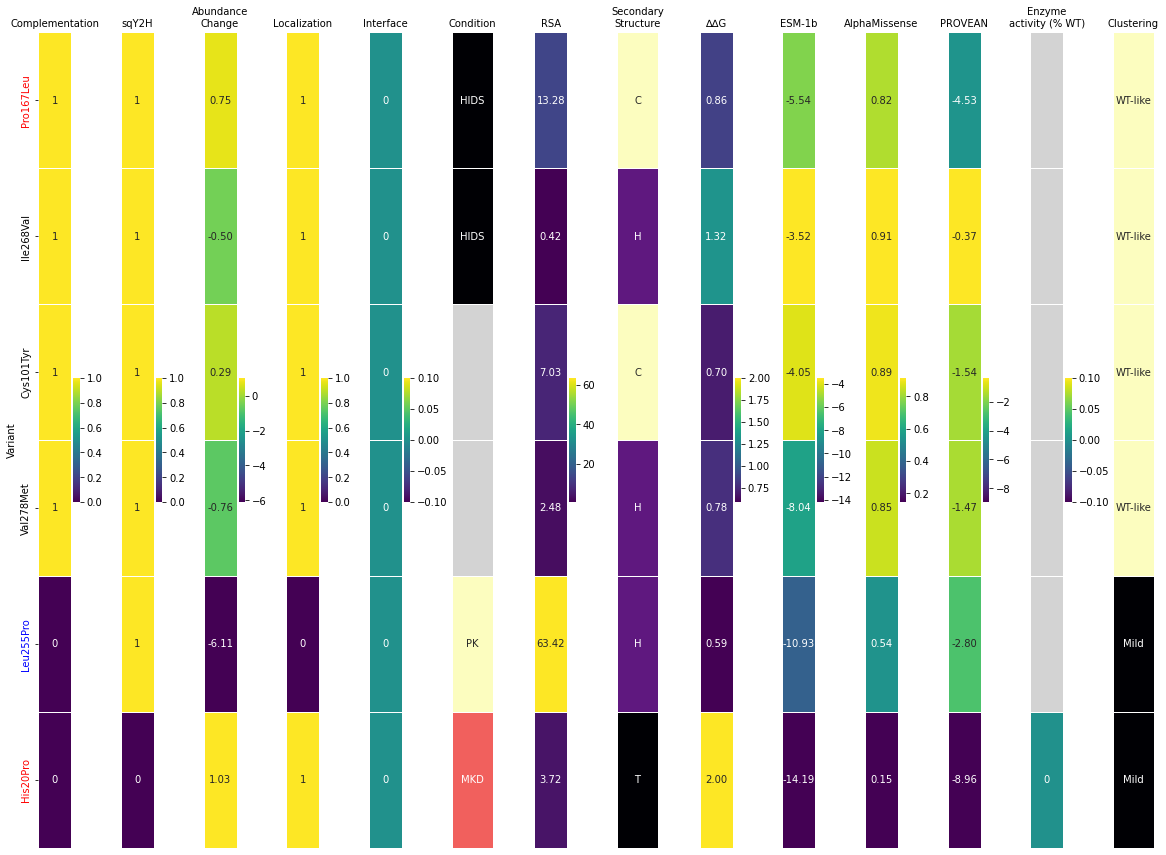

In [ ]:
# Print and save fig

grey = mcolors.to_rgba('grey')
colors = {'Benign': 'green', 'Conflicting': 'orange', 'Pathogenic': 'red', 'VUS': 'blue', np.nan: 'black'}

fig, axs = plt.subplots(nrows=1, ncols=14, figsize=(20, 15))

names_array = [[v] for v in infevers_conditions_names_dict.values()]

ss_array = [[v] for v in ss_dict.values()]

clust_array = [[v] for v in clustering_dict.values()]

decimals_indexes = [2, 6, 8, 9, 10, 11, 13]


for i, dico in enumerate([growth_dict, ppi_dict, abundance_dict, mislocalization_dict, contact_dict, infevers_conditions_dict, solvent_acc_dict, ss_digits_dict, ddg_dict, esm_dict, am_dict, provean_dict, enzymatic_dict, clustering_digits_dict]):
    var_labels = list(dico.keys())
    scores = list(dico.values())
    scores_array = np.array(scores).reshape(-1, 1)
    

        
    if i == 5:
        heatmap = sns.heatmap(scores_array, cmap='magma', annot=names_array, fmt='', linewidths=.5,
                            cbar=False if i == 5 or i == 7 else True, ax=axs[i], square=False, xticklabels=[], yticklabels=var_labels if i == 0 else [],
                            cbar_kws={'shrink': .5})
        heatmap.set_facecolor('lightgrey')
    elif i == 7:
        heatmap = sns.heatmap(scores_array, cmap='magma', annot=ss_array, fmt='', linewidths=.5,
                            cbar=False if i == 5 or i == 7 else True, ax=axs[i], square=False, xticklabels=[], yticklabels=var_labels if i == 0 else [],
                            cbar_kws={'shrink': .5})
        heatmap.set_facecolor('lightgrey')
        
    elif i == 13:
        heatmap = sns.heatmap(scores_array, cmap='magma', annot=clust_array, fmt='', linewidths=.5,
                            cbar=False if i == 5 or i == 7 or i == 13 else True, ax=axs[i], square=False, xticklabels=[], yticklabels=var_labels if i == 0 else [],
                            cbar_kws={'shrink': .5})
        heatmap.set_facecolor('lightgrey')
        
        
    else:
        heatmap = sns.heatmap(scores_array, cmap='viridis', annot=True, fmt='.2f' if i in decimals_indexes else '.0f', linewidths=.5,
                            cbar=True, ax=axs[i], square=False, xticklabels=[], yticklabels=var_labels if i == 0 else [],
                            cbar_kws={'shrink': .5})
        
    for label, color in zip(axs[i].get_yticklabels(), [colors.get(infevers_significance.get(var), 'black') for var in var_labels]):
        label.set_color(color)
        


    axs[0].set_ylabel('Variant', fontsize=10)
    axs[1].set_title('sqY2H', fontsize=10)
    axs[0].set_title('Complementation', fontsize=10)
    axs[2].set_title('Abundance\nChange', fontsize=10)
    axs[3].set_title('Localization', fontsize=10)
    axs[4].set_title('Interface', fontsize=10)
    axs[5].set_title('Condition', fontsize=10)
    axs[6].set_title('RSA', fontsize=10)
    axs[7].set_title('Secondary\nStructure', fontsize=10)
    axs[8].set_title('∆∆G', fontsize=10)
    axs[9].set_title('ESM-1b', fontsize=10) 
    axs[10].set_title('AlphaMissense', fontsize=10)
    axs[11].set_title('PROVEAN', fontsize=10)
    axs[12].set_title('Enzyme\nactivity (% WT)', fontsize=10)
    axs[13].set_title('Clustering', fontsize=10)
    
    heatmap.set_facecolor('lightgrey')

plt.subplots_adjust(wspace=1)

plt.savefig(output_folder / 'figs/variants_summary.pdf', format='pdf')

plt.show()

## Binary heatmaps

In [ ]:
# Sort the dataframe by PPI and Abundance

sorted_array = ['Ser52Asn', 'Asp386Asn', 'Val80Ile', 'Ile119Met', 'Thr209Ala', 'Thr243Ile', 'Ile268Val', 'Val377Ile', 'Pro288Leu', 'Cys101Tyr', 'Pro200Ser', 'Val278Met', 'Pro286Leu', 'Val293Met', 'Arg106His', 'Pro167Leu', 'Asn301Thr', 'Ala148Thr', 'Val250Ile', 'Tyr116His', 'Ile268Thr', 'Val5Ala', 'His20Pro', 'Pro165Leu', 'Gly211Ala', 'Leu265Pro', 'Ser329Asn', 'Leu41Pro', 'Leu255Pro']

mvk_df_sorted = mvk_df.sort_values(by='aa_change', key=lambda x: x.map(sorted_array.index)).reset_index(drop=True)
mvk_df_sorted

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,ESM1b,Provean,AM_binary,ESM1b_binary,Provean_binary,interface_residue,enzymatic_activity,clustering_ppi_abundance,clustering_ppi_abundance_digits,clustering_ppi_abundance_mislocalization
0,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,-3.517,-0.37,0,0,0,0,NaN,WT-like,2,WT-like
1,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,-4.048,-1.54,0,0,0,0,NaN,WT-like,2,WT-like
2,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,-8.043,-1.47,0,1,0,0,NaN,WT-like,2,WT-like
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,-5.542,-4.53,0,0,1,0,NaN,WT-like,2,WT-like
4,281,59A>C,His20Pro,MVK,ENSG00000110921,Pathogenic,3.0,vus,22,F03,...,-14.191,-8.96,1,1,1,0,0.0,Mild,1,Mild
5,281,764T>C,Leu255Pro,MVK,ENSG00000110921,Pathogenic,18.0,vus,28,D04,...,-10.926,-2.80,0,1,1,0,NaN,Mild,1,Strong


### PPI Abundance growth

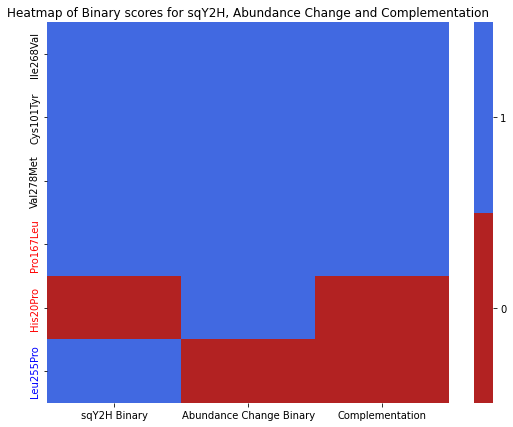

In [ ]:
fig, ax = plt.subplots(figsize=(9,7))

cmap = mcolors.ListedColormap(['firebrick', 'royalblue'])

sns.heatmap(data=mvk_df_sorted[['ppi_binary', 'abundance_binary','growth']], yticklabels=mvk_df_sorted['aa_change'], cmap=cmap, ax=ax, cbar_kws={'ticks': [0.25, 0.75], 'format': '%.0f'})

for label, classif in zip(ax.get_yticklabels(), mvk_df_sorted['clinical_significance_infevers']):
        label.set_color(colors[classif])
        
x_ticks = ['sqY2H Binary', 'Abundance Change Binary', 'Complementation']
ax.set_xticklabels(x_ticks)
plt.title('Heatmap of Binary scores for sqY2H, Abundance Change and Complementation')
plt.savefig(output_folder / 'figs/Heatmap_sqY2H_Abdundance_Compl.pdf', format='pdf')

        
plt.show()

### PPI Abundance Mislocalization Growth

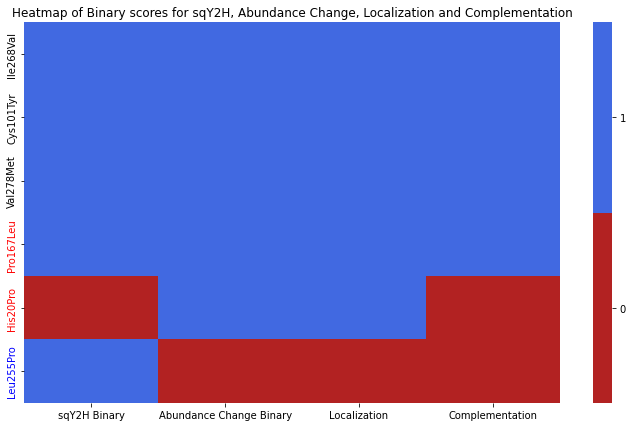

In [ ]:
fig, ax = plt.subplots(figsize=(12,7))

cmap = mcolors.ListedColormap(['firebrick', 'royalblue'])

sns.heatmap(data=mvk_df_sorted[['ppi_binary', 'abundance_binary', 'mislocalization_binary','growth']], yticklabels=mvk_df_sorted['aa_change'], cmap=cmap, ax=ax, cbar_kws={'ticks': [0.25, 0.75], 'format': '%.0f'})

for label, classif in zip(ax.get_yticklabels(), mvk_df_sorted['clinical_significance_infevers']):
        label.set_color(colors[classif])
        
x_ticks = ['sqY2H Binary', 'Abundance Change Binary', 'Localization', 'Complementation']
ax.set_xticklabels(x_ticks)
plt.title('Heatmap of Binary scores for sqY2H, Abundance Change, Localization and Complementation')
plt.savefig(output_folder / 'figs/Heatmap_sqY2H_Abdundance_Localization_Compl.pdf', format='pdf')

plt.show()

## Clustering figures

In [ ]:
colors_array = [colors.get(var, 'black') for var in infevers_significance.values()]

In [ ]:
def create_cluster_dict(name_array):
    cluster_dict = {}

    for i, row in mvk_df.iterrows():
        array = [row[col] for col in name_array]
        cluster_dict[row['aa_change']] = array

    return cluster_dict

In [ ]:
def plot_clustering(cluster_dict, title, outfile):
    variants_arrays = [np.array(cluster_dict[var]) for var in cluster_dict.keys()]
    variants_arrays_np = np.array(variants_arrays)
    
    jc_sim = 1 - pairwise_distances(variants_arrays_np, metric='jaccard')

    similarity_df = pd.DataFrame(jc_sim, columns=cluster_dict.keys(), index=cluster_dict.keys())
    similarity_df

    clstr = sns.clustermap(similarity_df, cmap='coolwarm_r', cbar_pos=(1, .25, .025, .5))

    for tick_label in clstr.ax_heatmap.axes.get_yticklabels():
        var_name = tick_label.get_text()
        color = colors.get(infevers_significance.get(var_name), 'black')
        tick_label.set_color(color)
        
    clstr.ax_heatmap.set_title(title)
    plt.savefig(output_folder / f'figs/{outfile}.pdf', format='pdf')
    plt.show()
    
    

### PPI Abundance

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/sklearn/metrics/pairwise.py:2181: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


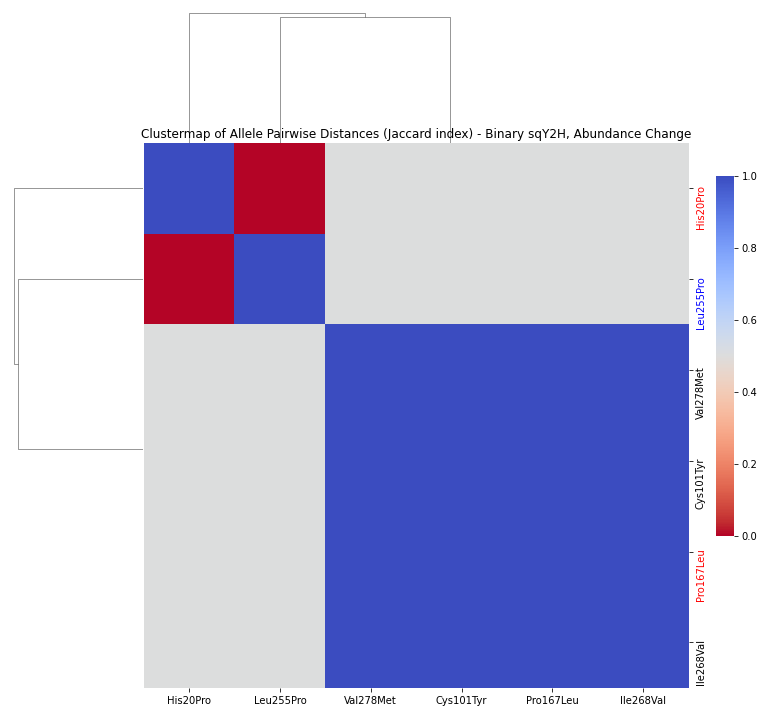

In [ ]:
ppi_abundance_dict = create_cluster_dict(['abundance_binary', 'ppi_binary'])

plot_clustering(ppi_abundance_dict, 'Clustermap of Allele Pairwise Distances (Jaccard index) - Binary sqY2H, Abundance Change', 'pairwise_jaccard_clustering_PPI_abundance')

### PPI Abundance Growth

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/sklearn/metrics/pairwise.py:2181: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


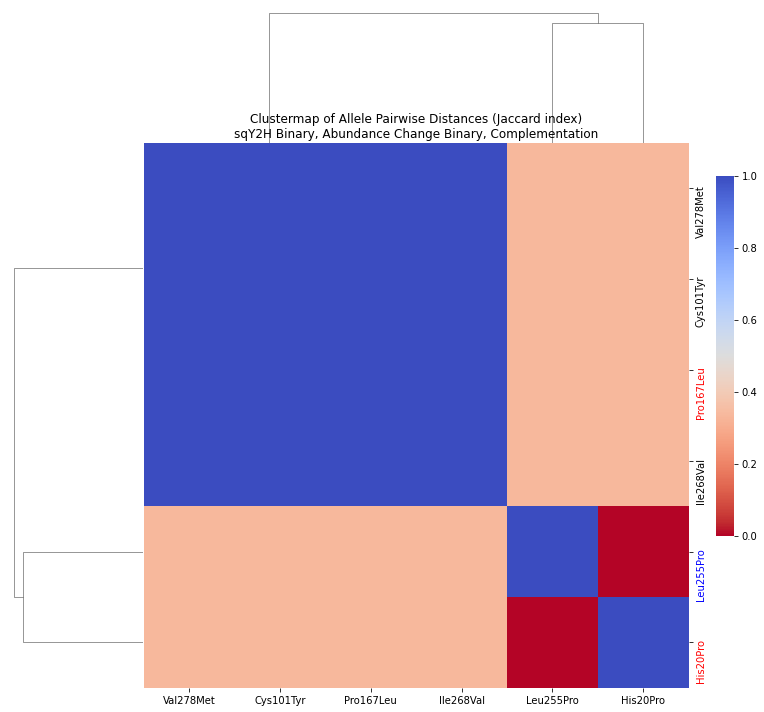

In [ ]:
ppi_abundance_growth_dict = create_cluster_dict(['abundance_binary', 'ppi_binary', 'growth'])

plot_clustering(ppi_abundance_growth_dict, 'Clustermap of Allele Pairwise Distances (Jaccard index)\nsqY2H Binary, Abundance Change Binary, Complementation', 'pairwise_jaccard_clustering_PPI_abundance_compl')

### PPI Abundance Loc

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/sklearn/metrics/pairwise.py:2181: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


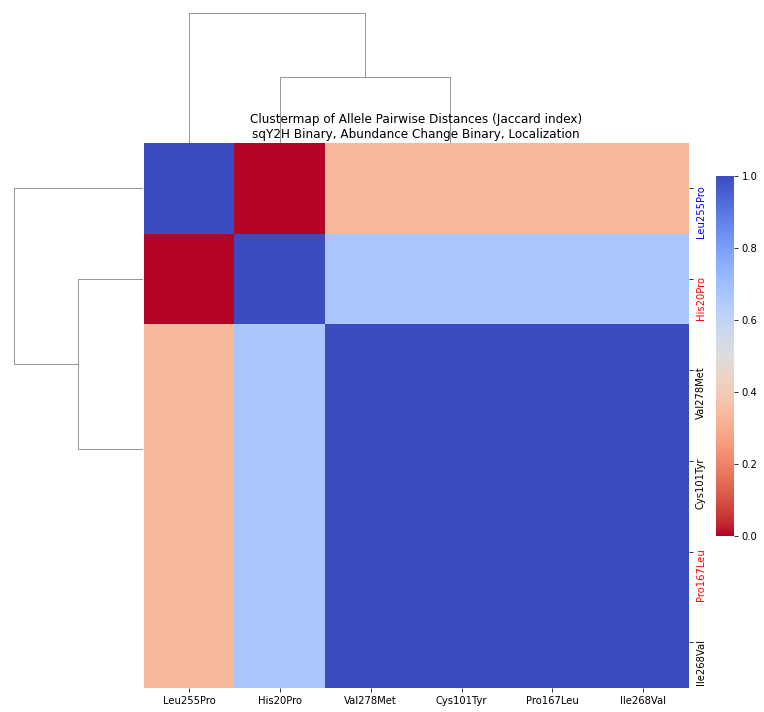

In [ ]:
ppi_abundance_loc_dict = create_cluster_dict(['abundance_binary', 'ppi_binary', 'mislocalization_binary'])

plot_clustering(ppi_abundance_loc_dict, 'Clustermap of Allele Pairwise Distances (Jaccard index)\nsqY2H Binary, Abundance Change Binary, Localization', 'pairwise_jaccard_clustering_PPI_abundance_localization')

### PPI Abundance Growth Loc

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/sklearn/metrics/pairwise.py:2181: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


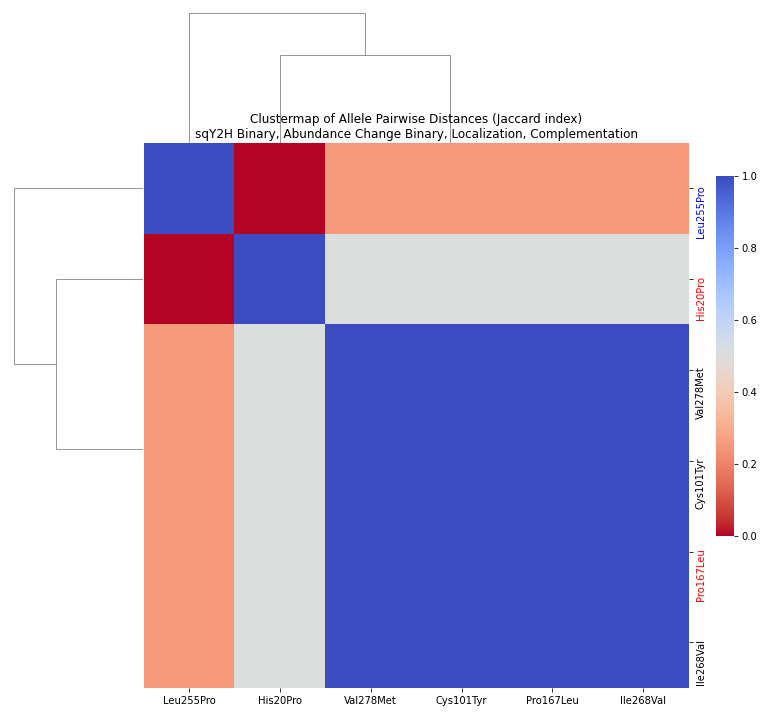

In [ ]:
ppi_abundance_growth_loc_dict = create_cluster_dict(['abundance_binary', 'ppi_binary', 'growth', 'mislocalization_binary'])

plot_clustering(ppi_abundance_growth_loc_dict, 'Clustermap of Allele Pairwise Distances (Jaccard index)\nsqY2H Binary, Abundance Change Binary, Localization, Complementation', 'pairwise_jaccard_clustering_PPI_abundance_localization_compl')

## Swarmplots

### PPI Abundance Growth

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/452010767.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mvk_df['growth'] = mvk_df['growth'].astype(int)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/452010767.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mvk_df['ppi'] = mvk_df['ppi'].astype(int)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/452010767.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be re

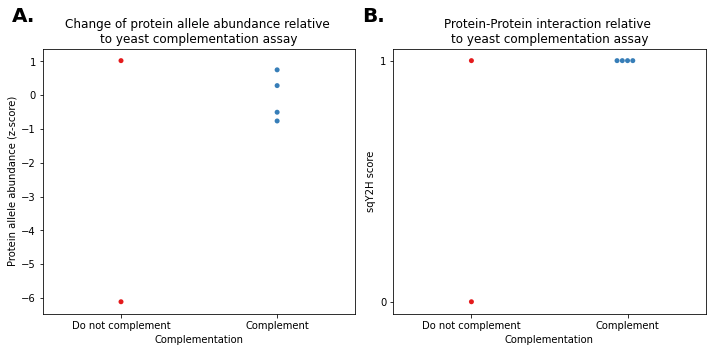

In [ ]:
mvk_df['growth'] = mvk_df['growth'].astype(int)
mvk_df['ppi'] = mvk_df['ppi'].astype(int)

fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 5))

sns.swarmplot(data=mvk_df, x='growth', y = 'z_abundance_change', ax=axes[0], palette='Set1')
x_ticks = ['Do not complement', 'Complement']
axes[0].set_xticklabels(x_ticks)
axes[0].set_title('Change of protein allele abundance relative \nto yeast complementation assay')
axes[0].set_xlabel('Complementation')
axes[0].set_ylabel('Protein allele abundance (z-score)')

sns.swarmplot(data=mvk_df, x='growth', y = 'ppi', ax=axes[1], palette='Set1')
y_ticks = mvk_df['ppi'].unique()
axes[1].set_yticks(y_ticks)
x_ticks = ['Do not complement', 'Complement']
axes[1].set_xticklabels(x_ticks)
axes[1].set_title('Protein-Protein interaction relative \nto yeast complementation assay')
axes[1].set_xlabel('Complementation')
axes[1].set_ylabel('sqY2H score')


for n, axes in enumerate(axes):
    axes.text(-0.1, 1.1, f'{string.ascii_uppercase[n]}.', transform=axes.transAxes, 
            size=20, weight='bold')

plt.subplots_adjust(hspace=0.3)
plt.tight_layout()

plt.savefig(output_folder / 'figs/PPI_abundance_compl_swarmplot.pdf', format='pdf')
plt.show()

### PPI binary abundance growth

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/1539929759.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mvk_df['growth'] = mvk_df['growth'].astype(int)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/1539929759.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mvk_df['ppi_binary'] = mvk_df['ppi_binary'].astype(int)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/1539929759.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecat

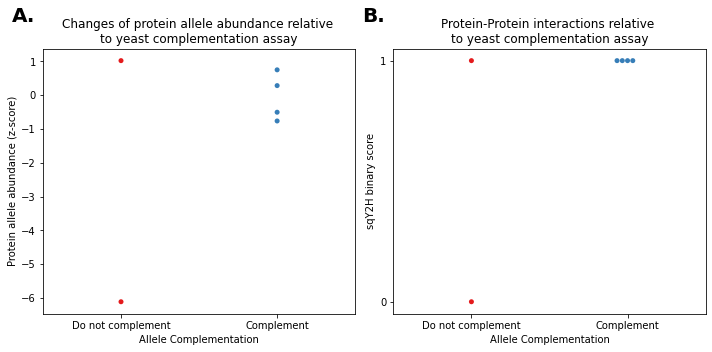

In [ ]:
mvk_df['growth'] = mvk_df['growth'].astype(int)
mvk_df['ppi_binary'] = mvk_df['ppi_binary'].astype(int)

fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 5))

sns.swarmplot(data=mvk_df, x='growth', y = 'z_abundance_change', ax=axes[0], palette='Set1')
axes[0].set_title('Changes of protein allele abundance relative \nto yeast complementation assay')
axes[0].set_xlabel('Allele Complementation')
x_ticks = ['Do not complement', 'Complement']
axes[0].set_xticklabels(x_ticks)
axes[0].set_ylabel('Protein allele abundance (z-score)')

sns.swarmplot(data=mvk_df, x='growth', y = 'ppi_binary', ax=axes[1], palette='Set1')
y_ticks = mvk_df['ppi_binary'].unique()
axes[1].set_yticks(y_ticks)
axes[1].set_title('Protein-Protein interactions relative \nto yeast complementation assay')
axes[1].set_xlabel('Allele Complementation')
x_ticks = ['Do not complement', 'Complement']
axes[1].set_xticklabels(x_ticks)
axes[1].set_ylabel('sqY2H binary score')


for n, axes in enumerate(axes):
    axes.text(-0.1, 1.1, f'{string.ascii_uppercase[n]}.', transform=axes.transAxes, 
            size=20, weight='bold')

plt.subplots_adjust(hspace=0.3)
plt.tight_layout()

plt.savefig(output_folder / 'figs/PPI_abundance_compl_swarmplot_binary.pdf', format='pdf')

plt.show()

### Mislocalization growth

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/3901548310.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(data=mvk_df_loc_no_na, x='growth', y='mislocalization_binary', ax=axes, palette='Set1')
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/3901548310.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes.set_xticklabels(x_ticks)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/3901548310.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes.set_xticklabels(x_ticks)


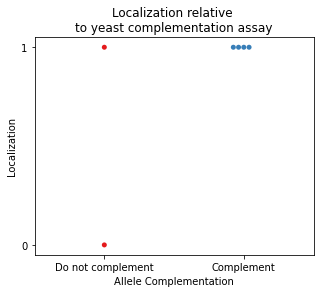

In [ ]:
mvk_df_loc_no_na = mvk_df.dropna(subset=['mislocalization_binary'])

mvk_df_loc_no_na['growth'] = mvk_df_loc_no_na['growth'].astype(int)
mvk_df_loc_no_na['mislocalization_binary'] = mvk_df_loc_no_na['mislocalization_binary'].astype(int)

fig, axes = plt.subplots(figsize=(5, 4))

sns.swarmplot(data=mvk_df_loc_no_na, x='growth', y='mislocalization_binary', ax=axes, palette='Set1')
axes.set_title('Localization relative \nto yeast complementation assay')
axes.set_xlabel('Allele Complementation')

x_ticks = ['Do not complement', 'Complement']
axes.set_xticklabels(x_ticks)

axes.set_ylabel('Localization')
axes.set_yticks([0, 1])  
axes.set_yticklabels(['0', '1'])

plt.savefig(output_folder / 'figs/mislocalization_growth_swarmplot.pdf', format='pdf')

plt.show()


### PPI Abundance Loc Growth combined

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/3345785664.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mvk_df['growth'] = mvk_df['growth'].astype(int)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/3345785664.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mvk_df['ppi_binary'] = mvk_df['ppi_binary'].astype(int)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/3345785664.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecat

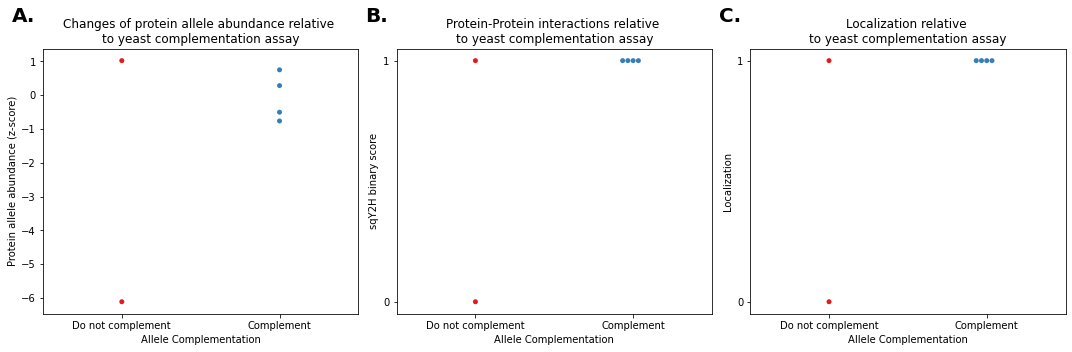

In [ ]:
mvk_df['growth'] = mvk_df['growth'].astype(int)
mvk_df['ppi_binary'] = mvk_df['ppi_binary'].astype(int)

fig, axes = plt.subplots(nrows = 1, ncols = 3, figsize = (15, 5))

sns.swarmplot(data=mvk_df, x='growth', y = 'z_abundance_change', ax=axes[0], palette='Set1')
axes[0].set_title('Changes of protein allele abundance relative \nto yeast complementation assay')
axes[0].set_xlabel('Allele Complementation')
x_ticks = ['Do not complement', 'Complement']
axes[0].set_xticklabels(x_ticks)
axes[0].set_ylabel('Protein allele abundance (z-score)')

sns.swarmplot(data=mvk_df, x='growth', y = 'ppi_binary', ax=axes[1], palette='Set1')
y_ticks = mvk_df['ppi_binary'].unique()
axes[1].set_yticks(y_ticks)
axes[1].set_title('Protein-Protein interactions relative \nto yeast complementation assay')
axes[1].set_xlabel('Allele Complementation')
x_ticks = ['Do not complement', 'Complement']
axes[1].set_xticklabels(x_ticks)
axes[1].set_ylabel('sqY2H binary score')

mvk_df_loc_no_na = mvk_df.dropna(subset=['mislocalization_binary'])

mvk_df_loc_no_na['growth'] = mvk_df_loc_no_na['growth'].astype(int)
mvk_df_loc_no_na['mislocalization_binary'] = mvk_df_loc_no_na['mislocalization_binary'].astype(int)

sns.swarmplot(data=mvk_df_loc_no_na, x='growth', y='mislocalization_binary', ax=axes[2], palette='Set1')
axes[2].set_title('Localization relative \nto yeast complementation assay')
axes[2].set_xlabel('Allele Complementation')

x_ticks = ['Do not complement', 'Complement']
axes[2].set_xticklabels(x_ticks)

axes[2].set_ylabel('Localization')
axes[2].set_yticks([0, 1])  
axes[2].set_yticklabels(['0', '1'])



for n, axes in enumerate(axes):
    axes.text(-0.1, 1.1, f'{string.ascii_uppercase[n]}.', transform=axes.transAxes, 
            size=20, weight='bold')

plt.subplots_adjust(hspace=0.3)
plt.tight_layout()

plt.savefig(output_folder / 'figs/PPI_abundance_misloc_compl_swarmplot_binary.pdf', format='pdf')

plt.show()

### Predictors vs clustering Abundance PPI

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/4153159394.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance', y = 'AM', ax=axs[0,0], palette=inverse_colors)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/4153159394.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance', y = 'ESM1b', ax=axs[0,1], palette=inverse_colors)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/4153159394.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the sa

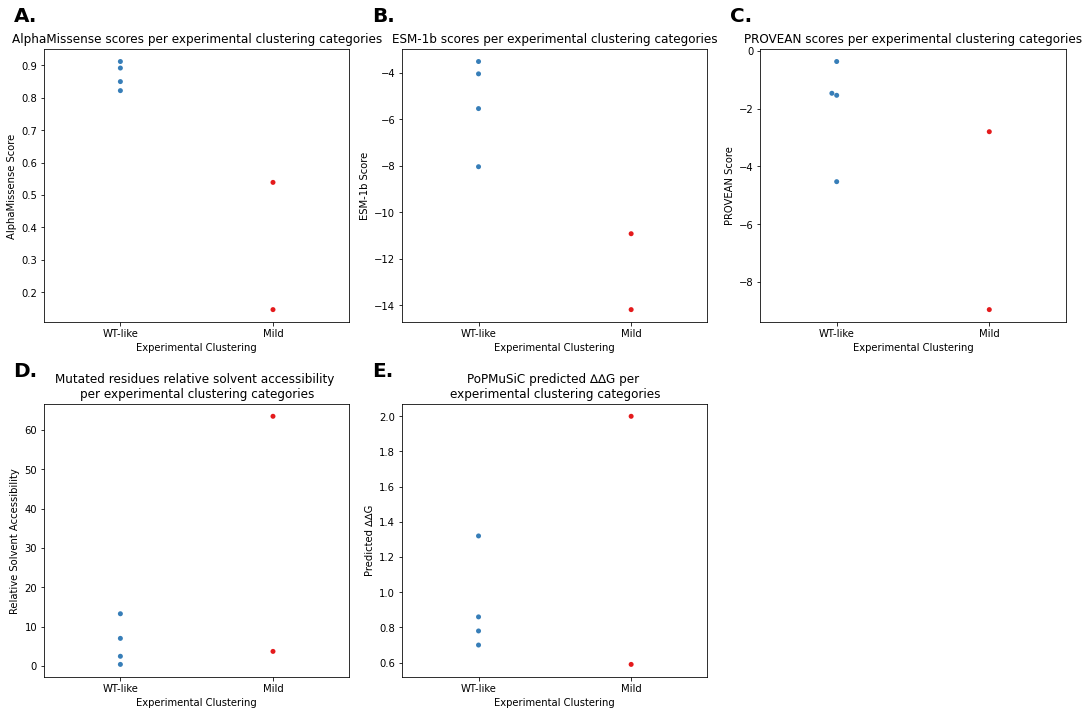

In [ ]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15,10))

colors = sns.color_palette('Set1', n_colors=len(mvk_df['clustering_ppi_abundance'].unique())).as_hex()
inverse_colors = colors[::-1]

sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance', y = 'AM', ax=axs[0,0], palette=inverse_colors)
axs[0,0].set_xlabel('Experimental Clustering')
axs[0,0].set_title('AlphaMissense scores per experimental clustering categories')
axs[0,0].set_ylabel('AlphaMissense Score')

sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance', y = 'ESM1b', ax=axs[0,1], palette=inverse_colors)
axs[0,1].set_title('ESM-1b scores per experimental clustering categories')
axs[0,1].set_xlabel('Experimental Clustering')
axs[0,1].set_ylabel('ESM-1b Score')

sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance', y = 'Provean', ax=axs[0,2], palette=inverse_colors)
axs[0,2].set_title('PROVEAN scores per experimental clustering categories')
axs[0,2].set_xlabel('Experimental Clustering')
axs[0,2].set_ylabel('PROVEAN Score')

sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance', y = 'solvent_accessibility', ax=axs[1,0], palette=inverse_colors)
axs[1,0].set_title('Mutated residues relative solvent accessibility \nper experimental clustering categories')
axs[1,0].set_xlabel('Experimental Clustering')
axs[1,0].set_ylabel('Relative Solvent Accessibility')

sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance', y = 'ddg', ax=axs[1,1], palette=inverse_colors)
axs[1,1].set_title('PoPMuSiC predicted ∆∆G per \nexperimental clustering categories')
axs[1,1].set_xlabel('Experimental Clustering')
axs[1,1].set_ylabel('Predicted ∆∆G')

axs[1,2].remove()

axs[0,0].set_xticklabels(['WT-like', 'Mild', 'Strong'])
axs[0,1].set_xticklabels(['WT-like', 'Mild', 'Strong'])
axs[0,2].set_xticklabels(['WT-like', 'Mild', 'Strong'])
axs[1,0].set_xticklabels(['WT-like', 'Mild', 'Strong'])
axs[1,1].set_xticklabels(['WT-like', 'Mild', 'Strong'])

for n, axes in enumerate(axs.flat):
    axes.text(-0.1, 1.1, f'{string.ascii_uppercase[n]}.', transform=axes.transAxes, 
            size=20, weight='bold')

plt.tight_layout()
plt.savefig(output_folder / 'figs/abundance_ppi_clustering_AM_ESM1b_Provean_∆∆G.pdf', format='pdf')
plt.subplots_adjust(hspace=0.3)

### Predictors vs clustering Abundance PPI misloc

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/3307015343.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mvk_df['clustering_ppi_abundance_mislocalization'] = pd.Categorical(mvk_df['clustering_ppi_abundance_mislocalization'], categories=category_order, ordered=True)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/3307015343.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance_mislocalization', y = 'AM', ax=axs[0,0], palette=inverse_colors)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/3307015343.py:

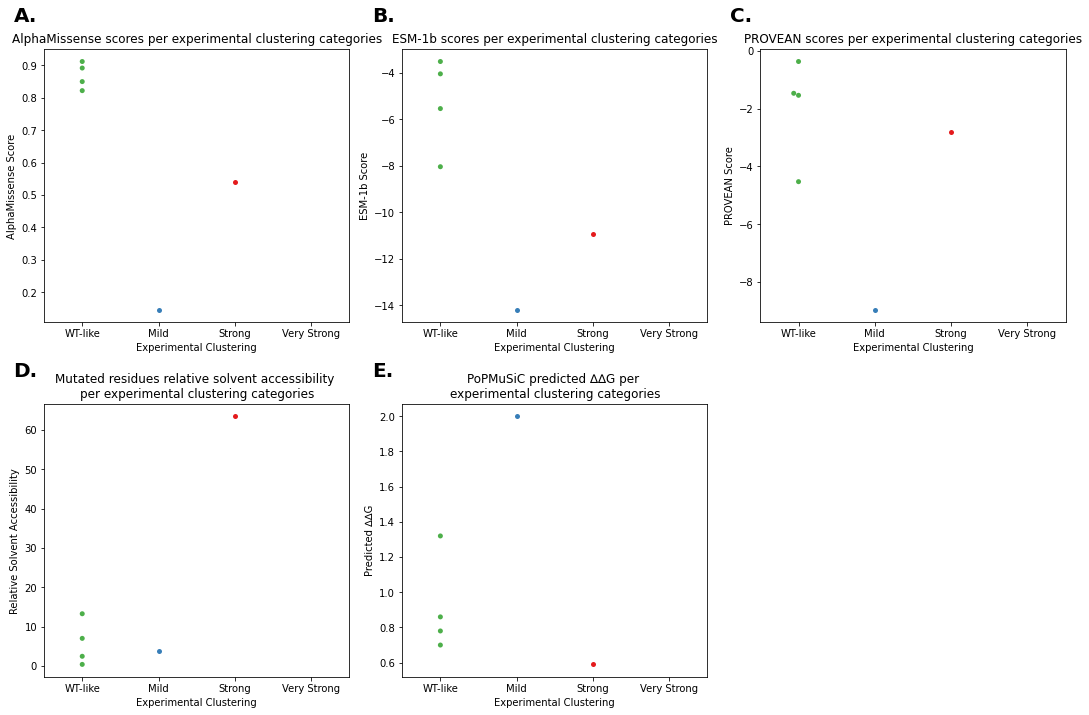

In [ ]:
category_order = ['WT-like', 'Mild', 'Strong', 'Very Strong']
mvk_df['clustering_ppi_abundance_mislocalization'] = pd.Categorical(mvk_df['clustering_ppi_abundance_mislocalization'], categories=category_order, ordered=True)


fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15,10))

colors = sns.color_palette('Set1', n_colors=len(mvk_df['clustering_ppi_abundance_mislocalization'].unique())).as_hex()
inverse_colors = colors[::-1]

sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance_mislocalization', y = 'AM', ax=axs[0,0], palette=inverse_colors)
axs[0,0].set_xlabel('Experimental Clustering')
axs[0,0].set_title('AlphaMissense scores per experimental clustering categories')
axs[0,0].set_ylabel('AlphaMissense Score')

sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance_mislocalization', y = 'ESM1b', ax=axs[0,1], palette=inverse_colors)
axs[0,1].set_title('ESM-1b scores per experimental clustering categories')
axs[0,1].set_xlabel('Experimental Clustering')
axs[0,1].set_ylabel('ESM-1b Score')

sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance_mislocalization', y = 'Provean', ax=axs[0,2], palette=inverse_colors)
axs[0,2].set_title('PROVEAN scores per experimental clustering categories')
axs[0,2].set_xlabel('Experimental Clustering')
axs[0,2].set_ylabel('PROVEAN Score')

sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance_mislocalization', y = 'solvent_accessibility', ax=axs[1,0], palette=inverse_colors)
axs[1,0].set_title('Mutated residues relative solvent accessibility \nper experimental clustering categories')
axs[1,0].set_xlabel('Experimental Clustering')
axs[1,0].set_ylabel('Relative Solvent Accessibility')

sns.swarmplot(data=mvk_df, x='clustering_ppi_abundance_mislocalization', y = 'ddg', ax=axs[1,1], palette=inverse_colors)
axs[1,1].set_title('PoPMuSiC predicted ∆∆G per \nexperimental clustering categories')
axs[1,1].set_xlabel('Experimental Clustering')
axs[1,1].set_ylabel('Predicted ∆∆G')

axs[1,2].remove()


axs[0,0].set_xticklabels(['WT-like', 'Mild', 'Strong', 'Very Strong'])
axs[0,1].set_xticklabels(['WT-like', 'Mild', 'Strong', 'Very Strong'])
axs[0,2].set_xticklabels(['WT-like', 'Mild', 'Strong', 'Very Strong'])
axs[1,0].set_xticklabels(['WT-like', 'Mild', 'Strong', 'Very Strong'])
axs[1,1].set_xticklabels(['WT-like', 'Mild', 'Strong', 'Very Strong'])

for n, axes in enumerate(axs.flat):
    axes.text(-0.1, 1.1, f'{string.ascii_uppercase[n]}.', transform=axes.transAxes, 
            size=20, weight='bold')

plt.tight_layout()
plt.savefig(output_folder / 'figs/abundance_ppi_misloc_clustering_AM_ESM1b_Provean_∆∆G.pdf', format='pdf')
plt.subplots_adjust(hspace=0.3)

### gnomAD

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/57096329.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=mvk_df, x='clustering_ppi_abundance', y='gnomAD_AF', ax=axs, palette=inverse_colors)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27991/57096329.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs.set_xticklabels(x_labels)


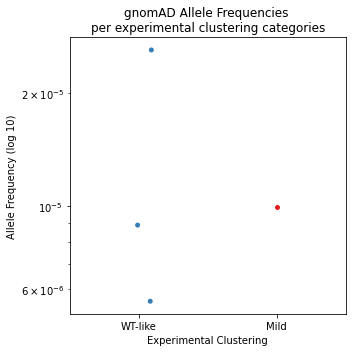

In [ ]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5,5))

x_labels = ['WT-like', 'Mild', 'Strong']

colors = sns.color_palette('Set1', n_colors=len(mvk_df['clustering_ppi_abundance'].unique())).as_hex()
inverse_colors = colors[::-1]

sns.stripplot(data=mvk_df, x='clustering_ppi_abundance', y='gnomAD_AF', ax=axs, palette=inverse_colors)
axs.set_title('gnomAD Allele Frequencies \nper experimental clustering categories')
axs.set_xlabel('Experimental Clustering')
axs.set_ylabel('Allele Frequency (log 10)')
axs.set_xticklabels(x_labels)


axs.set_yscale('log')

plt.subplots_adjust(hspace=0.6)
plt.tight_layout()
plt.savefig(output_folder / 'figs/gnomAD_clustering.pdf', format='pdf')

plt.show()

# Stats

## Definitions

### Permutation test

In [ ]:
def permutation_test(data_1, data_2):
    import matplotlib.pyplot as plt
    import numpy as np
    import seaborn as sns
    
    '''
    Takes as input two groups of data to compare the means using a permutation test
    Returns a graph showing the difference of the means of the input data against a 10000 random mean's differences distribution and the p-value of the test
    '''
    
    all_data = np.append(data_1, data_2)
    size_1 = len(data_1)

    def compute_means(arr1, arr2):
        arr1 = np.array(arr1)
        arr2 = np.array(arr2)
        
        mean_1 = np.mean(arr1)
        mean_2 = np.mean(arr2)
        
        mean_diff = mean_1 - mean_2
        
        return mean_1, mean_2, mean_diff

    mean_diff_exp = compute_means(data_1, data_2)[2]


    random_means = []

    for i in range(0, 10000, 1):
        np.random.shuffle(all_data)
        group_1, group_2 = all_data[:size_1], all_data[size_1:]
        
        mean_diff = compute_means(group_1, group_2)[2]
        
        random_means.append(mean_diff)

    fig = sns.kdeplot(random_means, fill=True)
    plt.axvline(mean_diff_exp, color='red')


    above = np.sum(random_means > mean_diff_exp)

    ratio = above/len(random_means)

    return fig, ratio
    

### Fisher test

In [ ]:
def fisher_test(col1, col2):
    table = pd.crosstab(mvk_df[col1], mvk_df[col2])

    np_table = np.array(table)

    stats, p = fisher_exact(np_table)

    return stats, p


### Mann-Whitney test

In [ ]:
def MWU(cluster1, cluster2, col, with_loc=False):
    if with_loc:
        data1 = mvk_df[mvk_df.clustering_ppi_abundance_mislocalization == cluster1][col].dropna().tolist()
        data2 = mvk_df[mvk_df.clustering_ppi_abundance_mislocalization == cluster2][col].dropna().tolist()
    else:
        data1 = mvk_df[mvk_df.clustering_ppi_abundance == cluster1][col].dropna().tolist()
        data2 = mvk_df[mvk_df.clustering_ppi_abundance == cluster2][col].dropna().tolist()
        
    stats, p = mannwhitneyu(data1, data2)
    
    return stats, p

## Permutation Abundance growth

0.2653

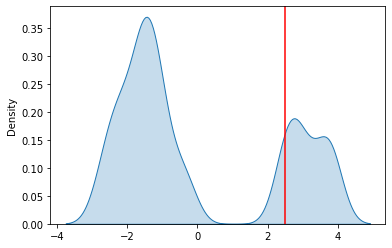

In [ ]:
abundance_growth = mvk_df[mvk_df.growth == 1].abundance.tolist()
abundance_no_growth = mvk_df[mvk_df.growth == 0].abundance.tolist()

fig, ratio = permutation_test(abundance_growth, abundance_no_growth)
ratio

## Permutation gnomAD

0.5079

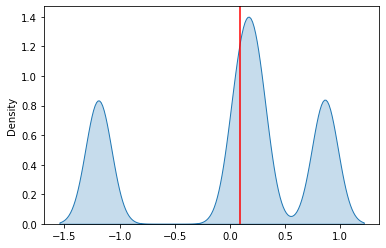

In [ ]:
af_wt = mvk_df[mvk_df.clustering_ppi_abundance == 'WT-like'].gnomAD_AF.dropna().tolist()
af_mild = mvk_df[mvk_df.clustering_ppi_abundance == 'Mild'].gnomAD_AF.dropna().tolist()

fig, ratio = permutation_test(np.log(af_wt), np.log(af_mild))
ratio


## Fisher Abundance Growth

In [ ]:
stats, p = fisher_test('abundance_binary', 'growth')
p

0.3333333333333333

## Fisher Abundance PPI

In [ ]:
stats, p = fisher_test('abundance_binary', 'ppi_binary')
p

1.0

## MWU

In [ ]:
def run_multiple_MWU(cluster_array, column, with_loc=False):
    pairwise_combinations = list(itertools.combinations(cluster_array, 2))
    for combo in pairwise_combinations:
        print(combo[0], 'vs', combo[1])
        stats, p = MWU(combo[0], combo[1], column, with_loc=with_loc)
        print(p)
        if p < 0.05:
            print('\tSignificant')
        print()

In [ ]:
cluster_array = ['WT-like', 'Mild', 'Strong']
cluster_loc_array = ['WT-like', 'Mild', 'Strong', 'Very Strong']

### RSA

#### Cluster w/o loc

In [ ]:
run_multiple_MWU(cluster_array, 'solvent_accessibility')

WT-like vs Mild
0.5333333333333333

WT-like vs Strong


ValueError: `x` and `y` must be of nonzero size.

#### Cluster w/ loc

In [ ]:
run_multiple_MWU(cluster_loc_array, 'solvent_accessibility', with_loc=True)

WT-like vs Mild
1.0

WT-like vs Strong
0.36363636363636365

WT-like vs Very Strong
0.18181818181818182

Mild vs Strong
0.5

Mild vs Very Strong
0.4

Strong vs Very Strong
0.6666666666666666



### AlphaMissense

#### Cluster w/o loc

In [ ]:
run_multiple_MWU(cluster_array, 'AM')

WT-like vs Mild
0.5394605394605395

WT-like vs Strong
0.030303030303030304
	Significant

Mild vs Strong
0.13333333333333333



#### Cluster w/ loc

In [ ]:
run_multiple_MWU(cluster_loc_array, 'AM', with_loc=True)

WT-like vs Mild
0.9370629370629371

WT-like vs Strong
0.36363636363636365

WT-like vs Very Strong
0.030303030303030304
	Significant

Mild vs Strong
1.0

Mild vs Very Strong
0.2

Strong vs Very Strong
0.6666666666666666



### ESM

#### Cluster w/o loc

In [ ]:
run_multiple_MWU(cluster_array, 'ESM1b')

WT-like vs Mild
0.1058941058941059

WT-like vs Strong
0.030303030303030304
	Significant

Mild vs Strong
0.26666666666666666



#### Cluster w/ loc

In [ ]:
run_multiple_MWU(cluster_loc_array, 'ESM1b', with_loc=True)

WT-like vs Mild
0.2867132867132867

WT-like vs Strong
0.18181818181818182

WT-like vs Very Strong
0.030303030303030304
	Significant

Mild vs Strong
1.0

Mild vs Very Strong
0.4

Strong vs Very Strong
0.6666666666666666



### PROVEAN

#### Cluster w/o loc

In [ ]:
run_multiple_MWU(cluster_array, 'Provean')

WT-like vs Mild
1.0

WT-like vs Strong
0.2727272727272727

Mild vs Strong
0.8



#### Cluster w/ loc

In [ ]:
run_multiple_MWU(cluster_loc_array, 'Provean', with_loc=True)

WT-like vs Mild
0.8111888111888111

WT-like vs Strong
0.7272727272727273

WT-like vs Very Strong
0.2727272727272727

Mild vs Strong
1.0

Mild vs Very Strong
0.8

Strong vs Very Strong
1.0



### DDG

#### Cluster w/o loc

In [ ]:
run_multiple_MWU(cluster_array, 'ddg')

WT-like vs Mild
0.4535464535464536

WT-like vs Strong
0.12121212121212122

Mild vs Strong
0.26666666666666666



#### Cluster w/ loc

In [ ]:
run_multiple_MWU(cluster_loc_array, 'ddg', with_loc=True)

WT-like vs Mild
0.2167832167832168

WT-like vs Strong
0.7272727272727273

WT-like vs Very Strong
0.12121212121212122

Mild vs Strong
0.5

Mild vs Very Strong
0.4

Strong vs Very Strong
0.6666666666666666

0.4

Strong vs Very Strong
0.6666666666666666



# Compoud heterozygosity

## Network

In [ ]:
# Parse patients and variants data from the https://www.mdpi.com/2077-0383/10/8/1552 to build the cytoscape network for compound heterozygosity

patients_excel_path = input_folder / 'bibliography/jcm-10-01552-s001/TableS2_Patients-detailled-description_Revised.xlsx'
patients_df = pd.read_excel(patients_excel_path, 'Feuil2', skiprows=[0], header=0)

variants_excel_path = input_folder / 'bibliography/jcm-10-01552-s001/TableS1_Distribution-variants_Revised.xlsx'
variants_excel_df = pd.read_excel(variants_excel_path, 'Feuil2',  skiprows=[0,1], header=0)
variants_excel_df['aa_change'] = [var[3:-1] if var == var and len(var) > 3 else np.nan for var in variants_excel_df['Protein name']]

infevers_clin_sig_dict = {var.strip():classif for var, classif in zip(variants_excel_df.aa_change, variants_excel_df.Classification) if var == var} # dictionnary with clinical signifiance for all variants found in patients

In [ ]:
def is_missense(variant):
    missense_pattern = re.compile(r"p\.\([A-Z][a-z]{2}\d+[A-Z][a-z]{2}\)$")    
    return bool(missense_pattern.match(variant)) if pd.notna(variant) else False

patients_df_missense = patients_df[patients_df['Variant 1'].apply(is_missense) & patients_df['Variant 2'].apply(is_missense)] # keep only missense variants

tuple_dict = {} # dictionnary to store variant pairs, linked phenotype and number of observations

for i, row in patients_df_missense.iterrows():
    var1 = row['Variant 1'][3:-1].strip()
    var2 = row['Variant 2'][3:-1].strip()
    if var1 in mvk_df.aa_change.tolist() or var2 in mvk_df.aa_change.tolist(): # keep only variants present in MVK
        var_tuple = (var1, var2, row.Phenotype)
        if var_tuple in tuple_dict.keys():
            tuple_dict[var_tuple] += 1
        else:
            tuple_dict[var_tuple] = 1


var_network_df = pd.DataFrame([(k[0], k[1], k[2], v) for k, v in tuple_dict.items()], # create dataframe from dictionnary for pairs of variants, phenotype and number of observations for the network
                            columns = ['Variant1', 'Variant2', 'Phenotype','n_obs'])
                    
var_network_df['count_normalized'] = var_network_df.groupby(['Variant1', 'Variant2'])['n_obs'].transform(lambda x: x / x.sum()) # normalize the number of observations for each pair of variants
var_network_df.to_csv(output_folder / 'network/network.tsv', sep='\t') 

attribute_df = pd.DataFrame(set(var_network_df['Variant1'].unique().tolist() + var_network_df['Variant2'].unique().tolist()), columns=['aa_change']) # create dataframe for attributes of variants (nodes) for cytoscape
attribute_df['clustering'] = [clustering_dict.get(var, np.nan) for var in attribute_df.aa_change]
attribute_df['infevers_class'] = [infevers_clin_sig_dict[var] for var in attribute_df.aa_change]
attribute_df['AM'] = [extract_predictors_data(var)[0] for var in attribute_df.aa_change]
attribute_df['ESM1b'] = [extract_predictors_data(var)[1] for var in attribute_df.aa_change]
attribute_df['Provean'] = [extract_predictors_data(var)[2] for var in attribute_df.aa_change]
attribute_df['AM_binary'] = [1 if am < 0.2 else 0 for am in attribute_df.AM]
attribute_df['ESM1b_binary'] = [1 if am < -7 else 0 for am in attribute_df.ESM1b]
attribute_df['Provean_binary'] = [1 if am < -2.5 else 0 for am in attribute_df.Provean]
attribute_df['pred_sum'] = attribute_df['AM_binary'] + attribute_df['ESM1b_binary'] + attribute_df['Provean_binary']
attribute_df['growth'] = [growth_dict.get(var, np.nan) for var in attribute_df.aa_change]
attribute_df.to_csv(output_folder / 'network/nodes_attributes.tsv', sep='\t')
attribute_df

# The network.tsv file is used to create the network graph in cytoscape, variant1 as source node, variant2 as target node
# The node_attributes.tsv file is used to add attributes to the nodes in cytoscape to color/shape the nodes (refer to the cytoscape session)

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/Bio/PDB/Polypeptide.py:144: BiopythonDeprecationWarning: 'three_to_one' will be deprecated in a future release of Biopython in favor of 'Bio.PDB.Polypeptide.protein_letters_3to1'.
  warnings.warn(
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/Bio/PDB/Polypeptide.py:144: BiopythonDeprecationWarning: 'three_to_one' will be deprecated in a future release of Biopython in favor of 'Bio.PDB.Polypeptide.protein_letters_3to1'.
  warnings.warn(
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/Bio/PDB/Polypeptide.py:144: BiopythonDeprecationWarning: 'three_to_one' will be deprecated in a future release of Biopython in favor of 'Bio.PDB.Polypeptide.protein_letters_3to1'.
  warnings.warn(
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/Bio/PDB/Polypeptide.py:144: BiopythonDeprecationWarning: 'three_to_one' will be deprecated in a future release of Biopython in favor of 'Bio.PDB.

,aa_change,clustering,infevers_class,AM,ESM1b,Provean,AM_binary,ESM1b_binary,Provean_binary,pred_sum,growth
0,His20Pro,Mild,Pathogenic,0.1467,-14.191,-8.96,1,1,1,3,0.0
1,Ala334Thr,NaN,Pathogenic,0.4019,-11.271,-3.43,0,1,1,2,NaN
2,Val377Ile,NaN,Pathogenic,0.9026,-6.997,-0.56,0,0,0,0,NaN
3,Val250Ile,NaN,Likely pathogenic,0.8409,-9.704,-0.93,0,1,0,1,NaN


## Plotting predictor pairs relative to phenotype

In [ ]:
var_pred_sum_dict = attribute_df.set_index('aa_change')['pred_sum'].to_dict() # {variant:pred_sum}

var_network_df['pred_pair'] = [f'{min(var_pred_sum_dict[var1], var_pred_sum_dict[var2])}-{max(var_pred_sum_dict[var1], var_pred_sum_dict[var2])}' 
                               for var1, var2 in zip(var_network_df.Variant1, var_network_df.Variant2)] # {variant_pair:pred_pair}

var_pred_pheno_dict = {var:{'Asymptomatic':0,'MKD-HIDS':0, 'MKD':0, 'MKD atypic':0, 'MKD-MA':0} for var in var_network_df.pred_pair.unique()} # {pred_pair:{pheno:count}}

for pred_pair, pheno in zip(var_network_df.pred_pair, var_network_df.Phenotype):
    var_pred_pheno_dict[pred_pair][pheno] += 1 # add counts to the dict

categories = {'0-0':1, '0-1':2, '0-2':3, '1-2':4, '0-3':5, '1-3':6, '2-2':7, '2-3':8, '3-3':9} # for sorting

def sort_key(value):
    return categories[value]
    
var_pred_pheno_dict_sorted = dict(sorted(var_pred_pheno_dict.items(), key=lambda item: sort_key(item[0])))

n_observations = [(sum(v.values())) for v in var_pred_pheno_dict_sorted.values()] # number of observations per cluster for plotting

# normalizing
pheno_list = ['Asymptomatic','MKD-HIDS', 'MKD', 'MKD atypic', 'MKD-MA']
var_pred_pheno_dict_sorted_norm = {}

for k, v in var_pred_pheno_dict_sorted.items():
    var_pred_pheno_dict_sorted_norm[k] = {'Asymptomatic':0, 'MKD-HIDS':0, 'MKD':0, 'MKD atypic':0, 'MKD-MA':0}
    total = sum(v.values())
    for v2, pheno in zip(v.values(), pheno_list):
        norm_value = v2/total
        var_pred_pheno_dict_sorted_norm[k][pheno] = norm_value
        
clusters = var_pred_pheno_dict_sorted_norm.keys() # cluster names for plotting

pheno_counts = {'Asymptomatic': [], 'MKD-HIDS': [], 'MKD': [], 'MKD atypic': [], 'MKD-MA': []} # for plotting

for k, v in var_pred_pheno_dict_sorted_norm.items(): # filling the dict
    for k1, v1 in v.items():
        pheno_counts[k1].append(v1)

pheno_counts = {k: np.array(v) for k, v in pheno_counts.items()} # converting to numpy arrays for plotting

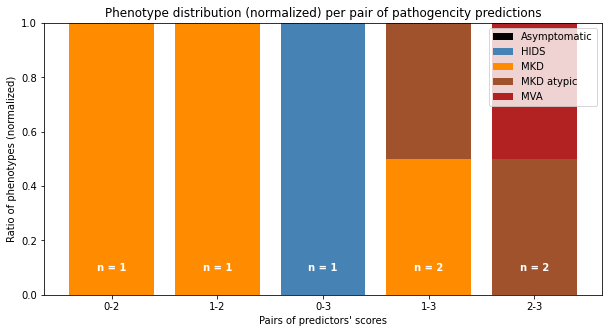

In [ ]:
# plotting

fig, ax = plt.subplots(figsize=(10,5))
bottom = np.zeros(len(clusters))

colors = {'Asymptomatic':'black','MKD': 'darkorange', 'MKD atypic': 'sienna', 'MKD-HIDS': 'steelblue', 'MKD-MA': 'firebrick'}

for pheno, counts in pheno_counts.items():
    p = ax.bar(clusters, counts, label = pheno, bottom=bottom, color=colors[pheno])
    bottom += counts

for i, count in enumerate(n_observations):
    ax.text(i, 0.1, f'n = {str(count)}', ha='center', va='center', color='white', fontweight='bold')


legend_labels = ['Asymptomatic','HIDS', 'MKD', 'MKD atypic', 'MVA']
plt.legend(legend_labels)
ax.set_xlabel('Pairs of predictors\' scores')
ax.set_ylabel('Ratio of phenotypes (normalized)')
plt.title('Phenotype distribution (normalized) per pair of pathogencity predictions')

plt.savefig(output_folder / 'figs/predictor_pairs_phenotypes.pdf', format='pdf')

plt.show()

## Plotting cluster pairs relative to phenotypes

In [ ]:
# Same approach but for cluster pairs

var_network_df['cluster_pair'] = [f'{min(clustering_dict[var1], clustering_dict[var2])}-{max(clustering_dict[var1], clustering_dict[var2])}' if var1 in clustering_dict.keys() and var2 in clustering_dict.keys() else np.nan for var1, var2 in zip(var_network_df.Variant1, var_network_df.Variant2)]

var_network_df_cluster_pair = var_network_df.dropna(subset='cluster_pair')

var_clust_pheno_dict = {var:{'Asymptomatic':0, 'MKD-HIDS':0, 'MKD':0, 'MKD atypic':0, 'MKD-MA':0} for var in var_network_df_cluster_pair.cluster_pair.unique()}

for clust_pair, pheno in zip(var_network_df_cluster_pair.cluster_pair, var_network_df_cluster_pair.Phenotype):
    var_clust_pheno_dict[clust_pair][pheno] += 1

categories = {'WT-like-WT-like':1, 'Mild-WT-like':2, 'Mild-Mild':3, 'Strong-WT-like':4, 'Mild-Strong':5}

    
var_clust_pheno_dict_sorted = dict(sorted(var_clust_pheno_dict.items(), key=lambda item: sort_key(item[0])))

n_obs = [sum(v.values()) for v in var_clust_pheno_dict_sorted.values()]

var_clust_pheno_dict_sorted_norm = {}

for k, v in var_clust_pheno_dict_sorted.items():
    var_clust_pheno_dict_sorted_norm[k] = {'Asymptomatic':0, 'MKD-HIDS':0, 'MKD':0, 'MKD atypic':0, 'MKD-MA':0}
    total = sum(v.values())
    for v2, pheno in zip(v.values(), pheno_list):
        norm_value = v2/total
        var_clust_pheno_dict_sorted_norm[k][pheno] = norm_value
        

clusters = var_clust_pheno_dict_sorted_norm.keys()

pheno_counts = {'Asymptomatic': [], 'MKD-HIDS': [], 'MKD': [], 'MKD atypic': [], 'MKD-MA': []}

for k, v in var_clust_pheno_dict_sorted_norm.items():
    for k1, v1 in v.items():
        pheno_counts[k1].append(v1)

pheno_counts = {k: np.array(v) for k, v in pheno_counts.items()}

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_99673/1200367721.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(x_ticks_labels)


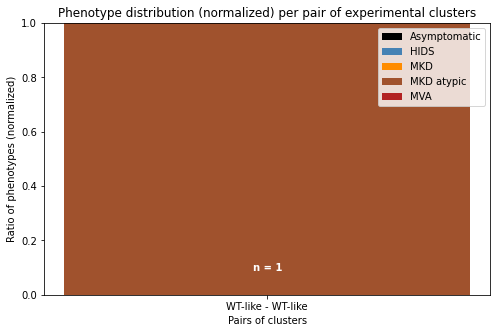

In [ ]:
# plotting

fig, ax = plt.subplots(figsize=(8,5))
bottom = np.zeros(len(clusters))

colors = {'Asymptomatic':'black', 'MKD': 'darkorange', 'MKD atypic': 'sienna', 'MKD-HIDS': 'steelblue', 'MKD-MA': 'firebrick'}

for pheno, counts in pheno_counts.items():
    p = ax.bar(clusters, counts, label = pheno, bottom=bottom, color=colors[pheno])
    bottom += counts
    

for i, count in enumerate(n_obs):
    ax.text(i, 0.1, f'n = {str(count)}', ha='center', va='center', color='white', fontweight='bold')
    
x_ticks_labels = ['WT-like - WT-like', 'Mild - WT-like', 'Mild - Mild', 'WT-like - Strong', 'Mild - Strong']
ax.set_xticklabels(x_ticks_labels)
legend_labels = ['Asymptomatic', 'HIDS', 'MKD', 'MKD atypic', 'MVA']
plt.legend(legend_labels)
ax.set_xlabel('Pairs of clusters')
ax.set_ylabel('Ratio of phenotypes (normalized)')
plt.title('Phenotype distribution (normalized) per pair of experimental clusters')
plt.savefig(output_folder / 'figs/cluster_pairs_phenotypes.pdf', format='pdf')

plt.show()

In [ ]:
mvk_df

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,ESM1b,Provean,AM_binary,ESM1b_binary,Provean_binary,interface_residue,enzymatic_activity,clustering_ppi_abundance,clustering_ppi_abundance_digits,clustering_ppi_abundance_mislocalization
2,281,238G>A,Val80Ile,MVK,ENSG00000110921,Conflicting,6.0,vus,3,C01,...,-4.387,-0.45,0,0,0,0,NaN,WT-like,2,WT-like
33,281,863C>T,Pro288Leu,MVK,ENSG00000110921,VUS,200097.0,cegs,34,B05,...,-4.233,-1.88,0,0,0,0,NaN,WT-like,2,WT-like
3,281,500C>T,Pro167Leu,MVK,ENSG00000110921,Pathogenic,13.0,vus,4,D01,...,-5.542,-4.53,0,0,1,0,NaN,WT-like,2,WT-like
5,281,357C>G,Ile119Met,MVK,ENSG00000110921,Pathogenic,200087.0,cegs,6,F01,...,-8.116,-2.23,0,1,0,0,NaN,WT-like,2,WT-like
8,281,625A>G,Thr209Ala,MVK,ENSG00000110921,Pathogenic,200091.0,cegs,9,A02,...,-6.961,-3.75,0,0,1,0,NaN,WT-like,2,WT-like
36,281,317G>A,Arg106His,MVK,ENSG00000110921,VUS,8.0,vus,37,E05,...,-3.733,-0.23,0,0,0,0,NaN,WT-like,2,WT-like
35,281,302G>A,Cys101Tyr,MVK,ENSG00000110921,VUS,7.0,vus,36,D05,...,-4.048,-1.54,0,0,0,0,NaN,WT-like,2,WT-like
28,281,802A>G,Ile268Val,MVK,ENSG00000110921,Pathogenic,19.0,vus,29,E04,...,-3.517,-0.37,0,0,0,0,NaN,WT-like,2,WT-like
38,281,832G>A,Val278Met,MVK,ENSG00000110921,VUS,21.0,vus,39,G05,...,-8.043,-1.47,0,1,0,0,NaN,WT-like,2,WT-like
37,281,598C>T,Pro200Ser,MVK,ENSG00000110921,VUS,14.0,vus,38,F05,...,-10.776,-7.73,0,1,1,0,NaN,WT-like,2,WT-like


In [ ]:
missing_list = [29.0,
200095.0,
200100.0,
200087.0,
200091.0,
200092.0,
200093.0,
200099.0,
200097.0,
200098.0,
727.0]

In [ ]:
missing_mvk = mvk_df[mvk_df['mut_id'].isin(missing_list)]
missing_mvk

,orf_id,nt_change,aa_change,symbol,ensg,clinical_significance,mut_id,source,dest_well_id,dest_well,...,ESM1b,Provean,AM_binary,ESM1b_binary,Provean_binary,interface_residue,enzymatic_activity,clustering_ppi_abundance,clustering_ppi_abundance_digits,clustering_ppi_abundance_mislocalization
33,281,863C>T,Pro288Leu,MVK,ENSG00000110921,VUS,200097.0,cegs,34,B05,...,-4.233,-1.88,0,0,0,0,NaN,WT-like,2,WT-like
5,281,357C>G,Ile119Met,MVK,ENSG00000110921,Pathogenic,200087.0,cegs,6,F01,...,-8.116,-2.23,0,1,0,0,NaN,WT-like,2,WT-like
8,281,625A>G,Thr209Ala,MVK,ENSG00000110921,Pathogenic,200091.0,cegs,9,A02,...,-6.961,-3.75,0,0,1,0,NaN,WT-like,2,WT-like
12,281,748G>A,Val250Ile,MVK,ENSG00000110921,Pathogenic,200093.0,cegs,13,E02,...,-9.704,-0.93,0,1,0,0,NaN,Mild,1,Mild
17,281,986G>A,Ser329Asn,MVK,ENSG00000110921,Pathogenic,200100.0,cegs,18,B03,...,-15.463,-2.30,1,1,0,0,NaN,Strong,0,Very Strong
